In [1]:
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp, ttest_ind
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
%load_ext autoreload
%autoreload 2
import os
NCPU = "5"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

In [2]:
all_models = {}
all_cms = {}
graphic_trains = {}
for i in range(5):
    split_thres = (0.6, 0.8)
    addon = 'downisiset'
    starting_from = 0.2*i
    downlims = [10,4,10]
    if addon=='downisiset':
        addon = f"{addon}{str(downlims)}{str(starting_from)[2]}"
    elif addon in ["downisitime", "downtime"]:
        addon += str(starting_from)[2]
    load_data = True

    train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, downlims,
                                                             starting_from=starting_from)
    graphic_trains[i] = get_extended_condensed_data(train_scaled)
    basic_log_models = train_multi_models(train_scaled, sampling_types=['over'])
    basic_log_cms = get_cms_multi(test_scaled, basic_log_models)
    all_models[i] = basic_log_models
    all_cms[i] = basic_log_cms

Loaded successfully


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2679/2679 [00:10<00:00, 252.86it/s]


Loaded successfully


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2679/2679 [00:10<00:00, 246.57it/s]


Loaded successfully


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2679/2679 [00:10<00:00, 261.83it/s]


Loaded successfully


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2679/2679 [00:10<00:00, 263.45it/s]


Loaded successfully


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2679/2679 [00:10<00:00, 266.67it/s]


0
1
2
3
4


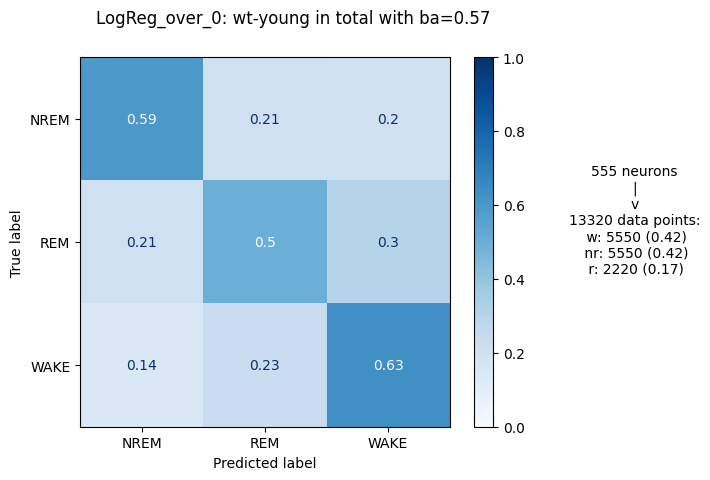

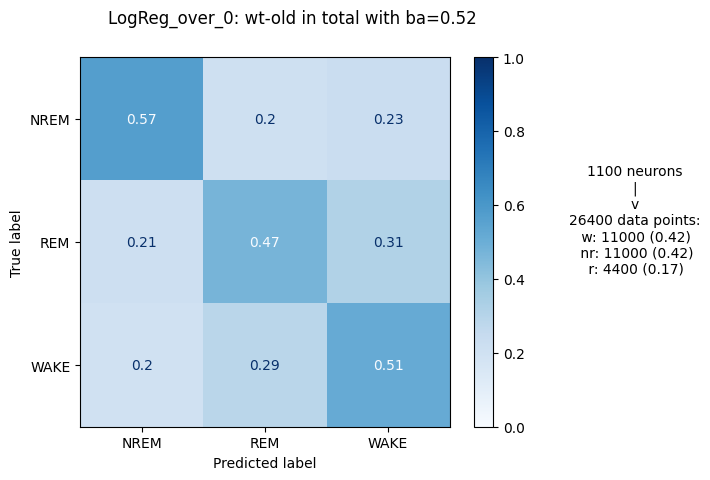

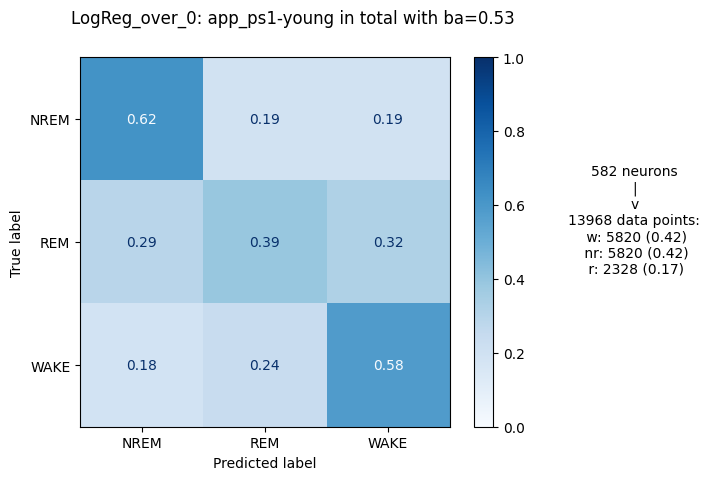

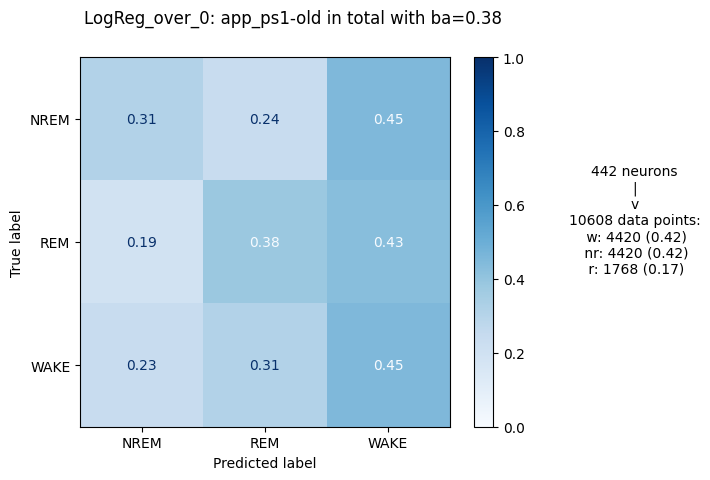

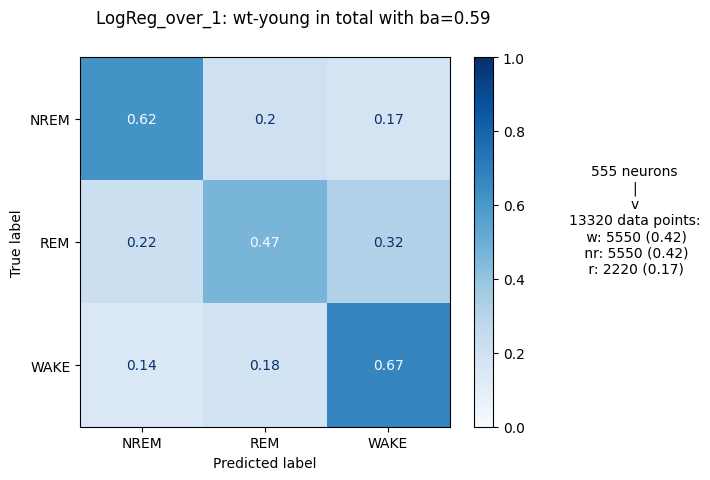

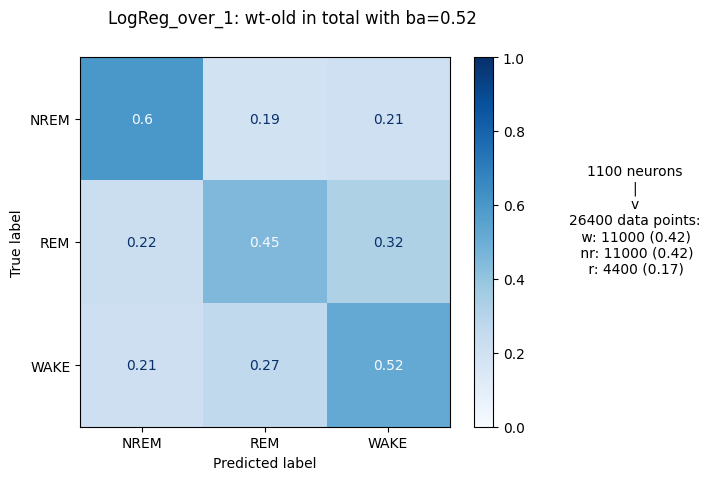

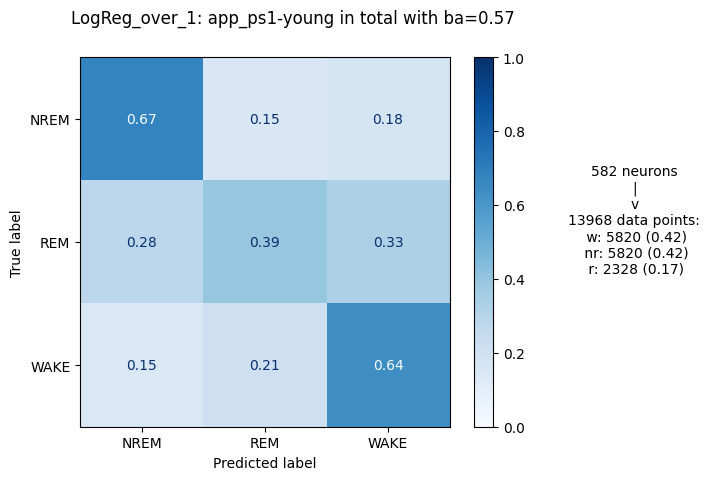

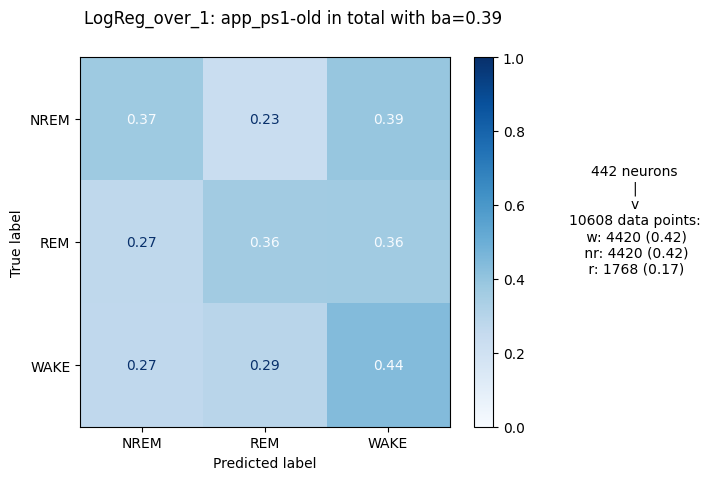

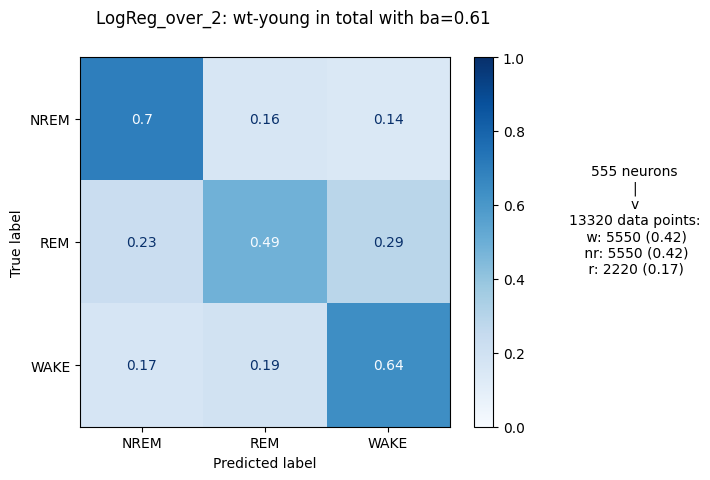

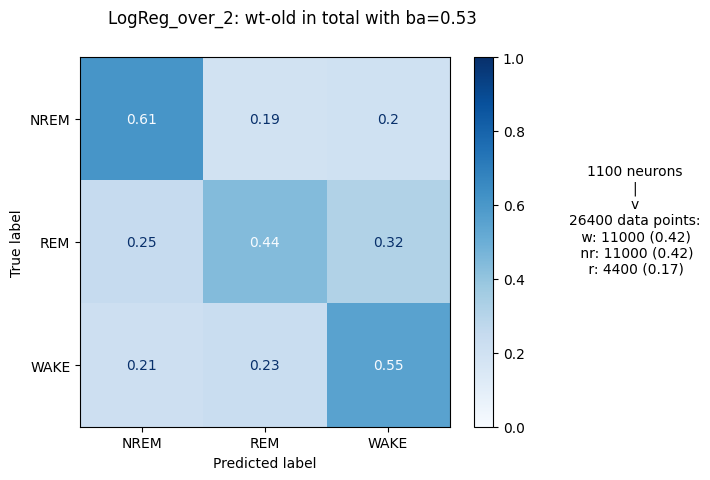

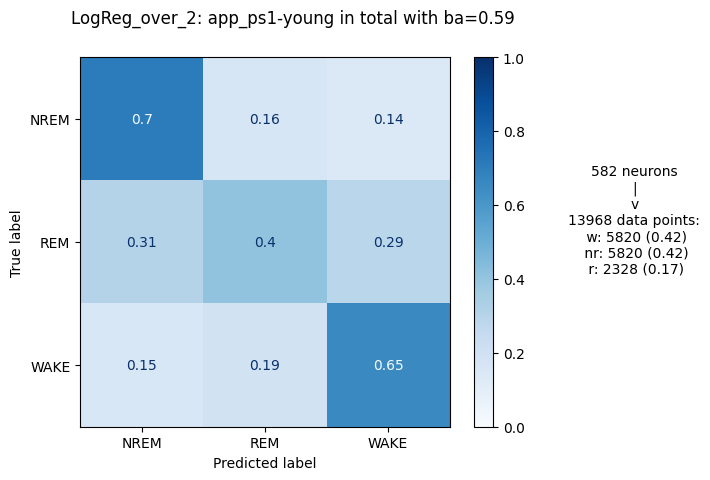

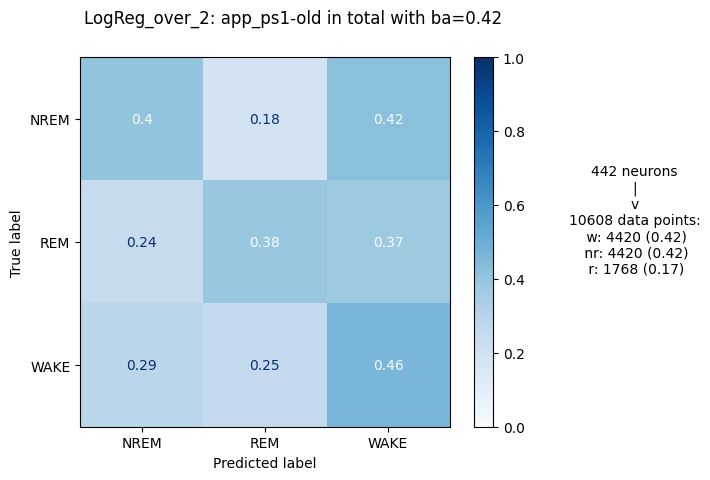

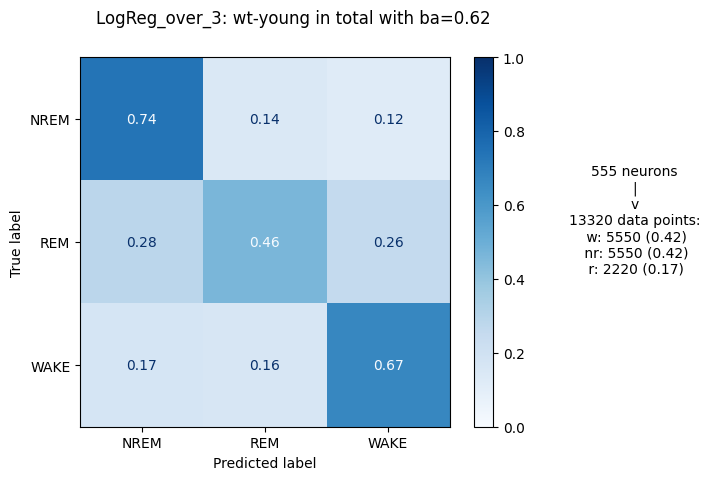

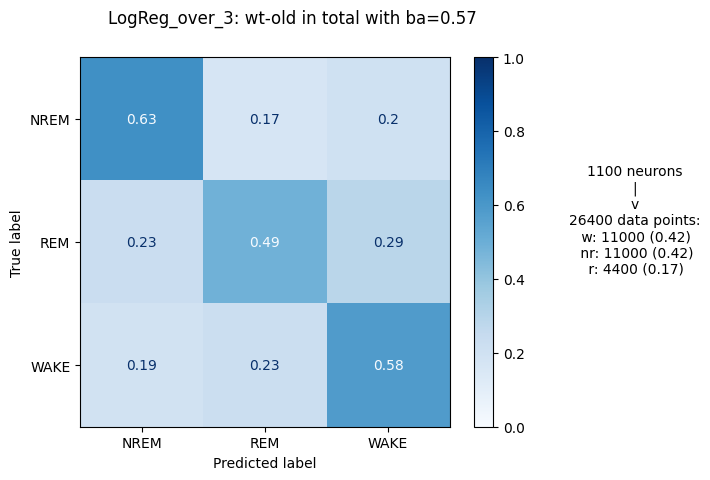

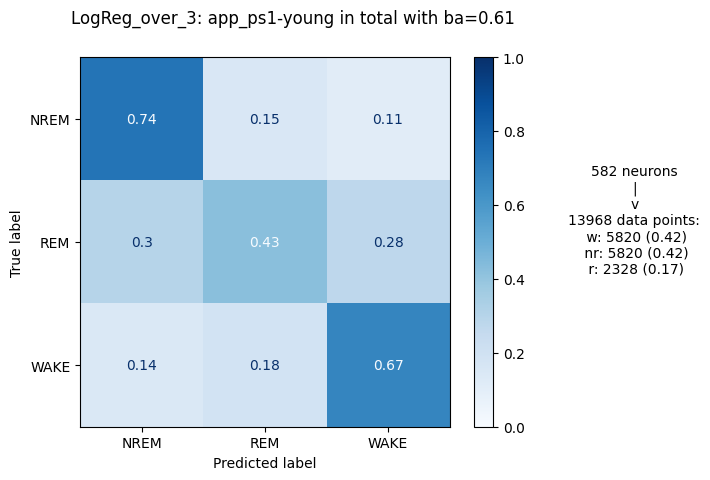

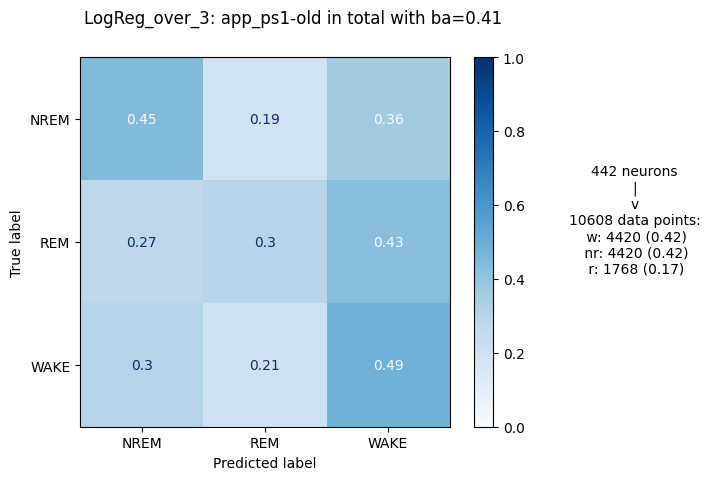

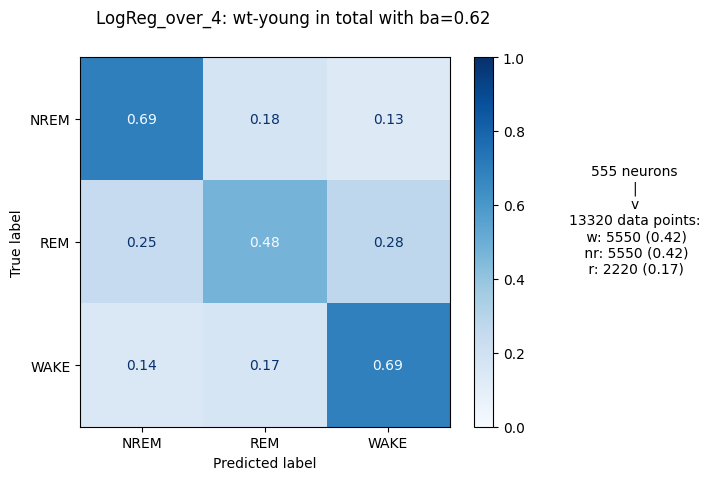

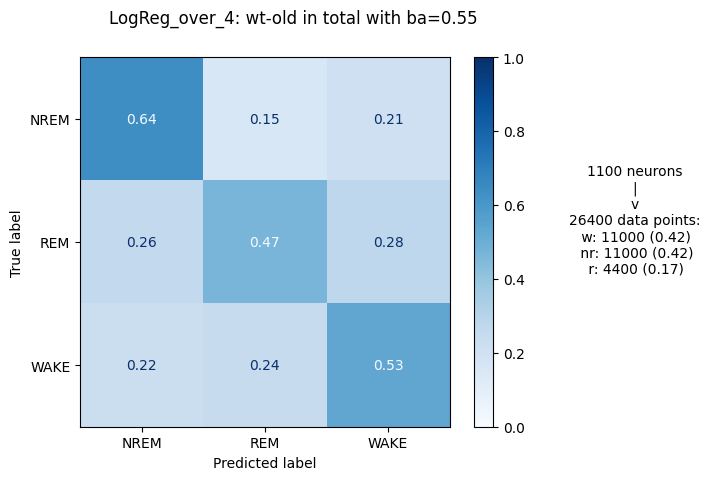

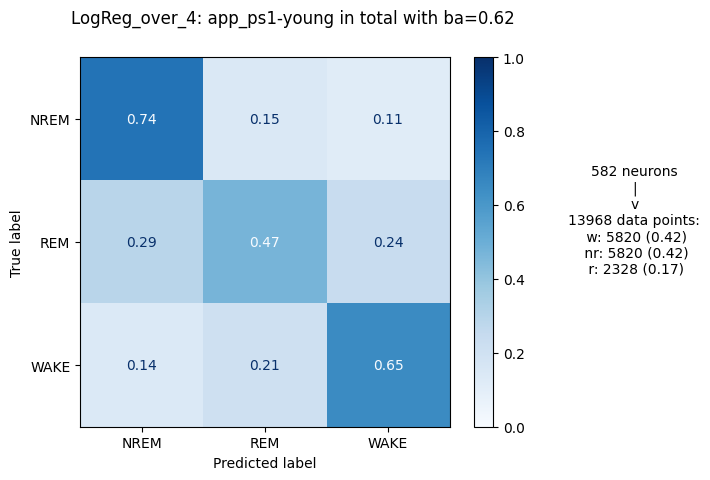

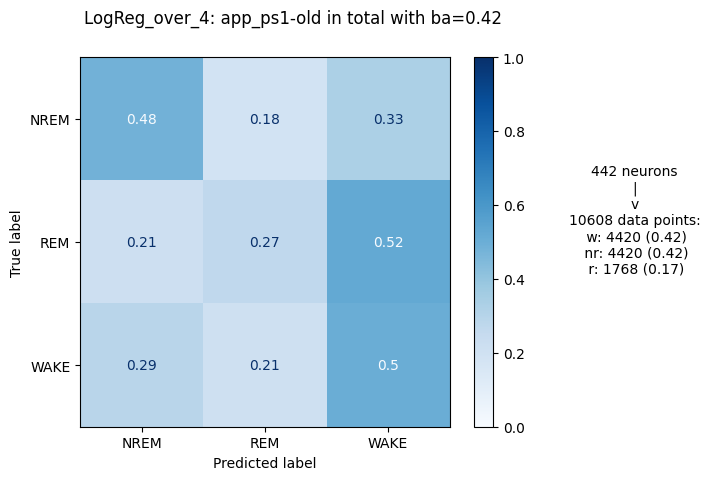

In [4]:
for cm_set in all_cms:
    print(cm_set)
    get_mean_cms_visual(all_cms[cm_set]['LogReg_over'], graphic_trains[cm_set], f'LogReg_over_{cm_set}', 
                        norm_size=3, subset={},
                        by_age=True, by_geno=True,
                        savefig=False, addon_suff='nrw', final_filters=[])

In [6]:
train_scaled.region.unique()

<ArrowStringArray>
['ACad', 'V1', 'RSPv', 'CA1']
Length: 4, dtype: str

In [8]:
train_scaled.cell.unique()

<ArrowStringArray>
[  'caf69_358_1228_0_12_0_wt',   'caf69_358_1228_0_12_1_wt',
   'caf69_358_1228_0_12_2_wt',   'caf69_358_1228_0_12_3_wt',
   'caf69_358_1228_0_12_4_wt',   'caf69_358_1228_0_12_5_wt',
   'caf69_358_1228_0_12_6_wt',   'caf69_358_1228_0_12_7_wt',
   'caf69_358_1228_0_12_8_wt',   'caf69_358_1228_0_12_9_wt',
 ...
 'bth100_99_0624_12_24_85_wt', 'bth100_99_0624_12_24_86_wt',
 'bth100_99_0624_12_24_87_wt', 'bth100_99_0624_12_24_88_wt',
 'bth100_99_0624_12_24_89_wt', 'bth100_99_0624_12_24_90_wt',
 'bth100_99_0624_12_24_91_wt', 'bth100_99_0624_12_24_92_wt',
 'bth100_99_0624_12_24_93_wt', 'bth100_99_0624_12_24_94_wt']
Length: 2679, dtype: str

In [4]:
wake_sleep_train = get_sleep_state_conversion(train_scaled)
wake_sleep_test = get_sleep_state_conversion(test_scaled)

In [9]:
graphic_train = get_extended_condensed_data(train_scaled)
#graphic_test = get_extended_condensed_data(test_scaled)

In [10]:
graphic_train

,index,state,region,cell,animal,celltype,geno,cell_no,age,age_group,state_str,cell_state,state_chunks
0,0,0,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,0,caf69_358_1228_0_12_0_wt-0,10
1,10,1,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,1,caf69_358_1228_0_12_0_wt-1,4
2,14,2,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,2,caf69_358_1228_0_12_0_wt-2,10
3,24,0,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,0,caf69_358_1228_0_12_1_wt-0,10
4,34,1,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,1,caf69_358_1228_0_12_1_wt-1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8032,64258,1,V1,bth100_99_0624_12_24_93_wt,bth100,FS,wt,93,99,young,1,bth100_99_0624_12_24_93_wt-1,4
8033,64262,2,V1,bth100_99_0624_12_24_93_wt,bth100,FS,wt,93,99,young,2,bth100_99_0624_12_24_93_wt-2,10
8034,64272,0,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,0,bth100_99_0624_12_24_94_wt-0,10
8035,64282,1,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,1,bth100_99_0624_12_24_94_wt-1,4


In [11]:
models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogReg'])
cms = get_cms_multi(test_scaled, models, get_spiking=True)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2679/2679 [00:09<00:00, 289.57it/s]


In [7]:
sw_models = train_multi_models(wake_sleep_train, sampling_types=['over'], methods=['LogReg'], num_states=2)
sw_cms = get_cms_multi(wake_sleep_test, sw_models, get_spiking=True)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [00:14<00:00, 289.34it/s]


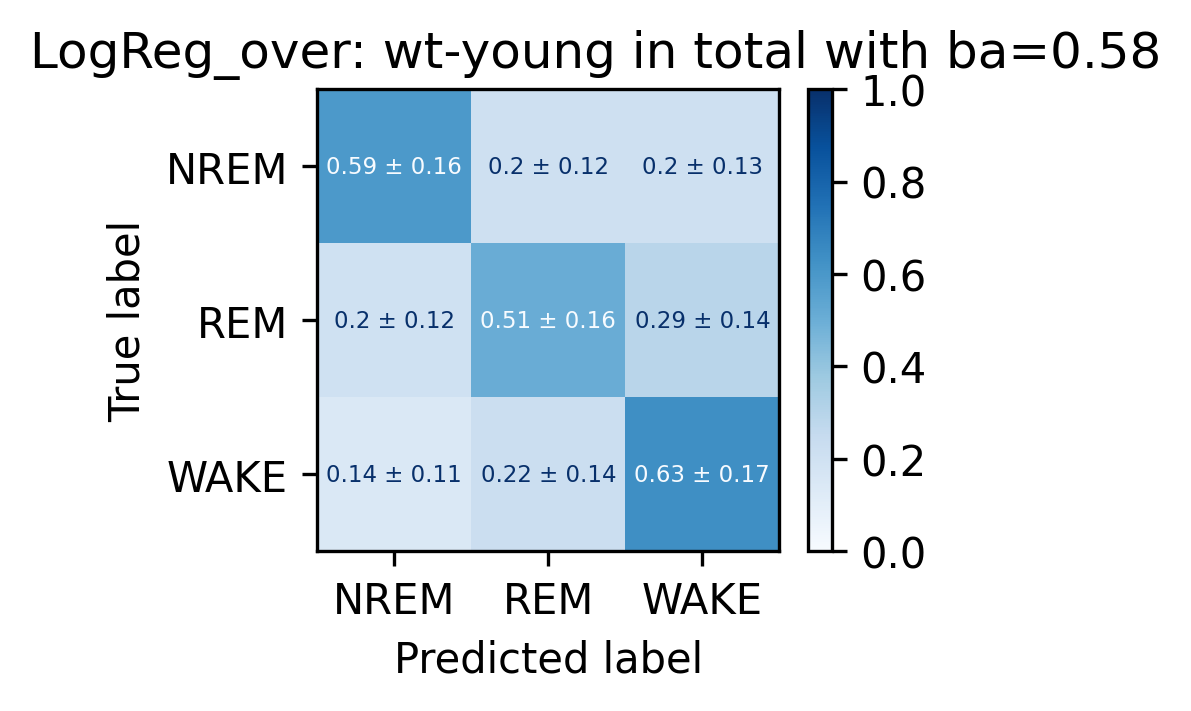

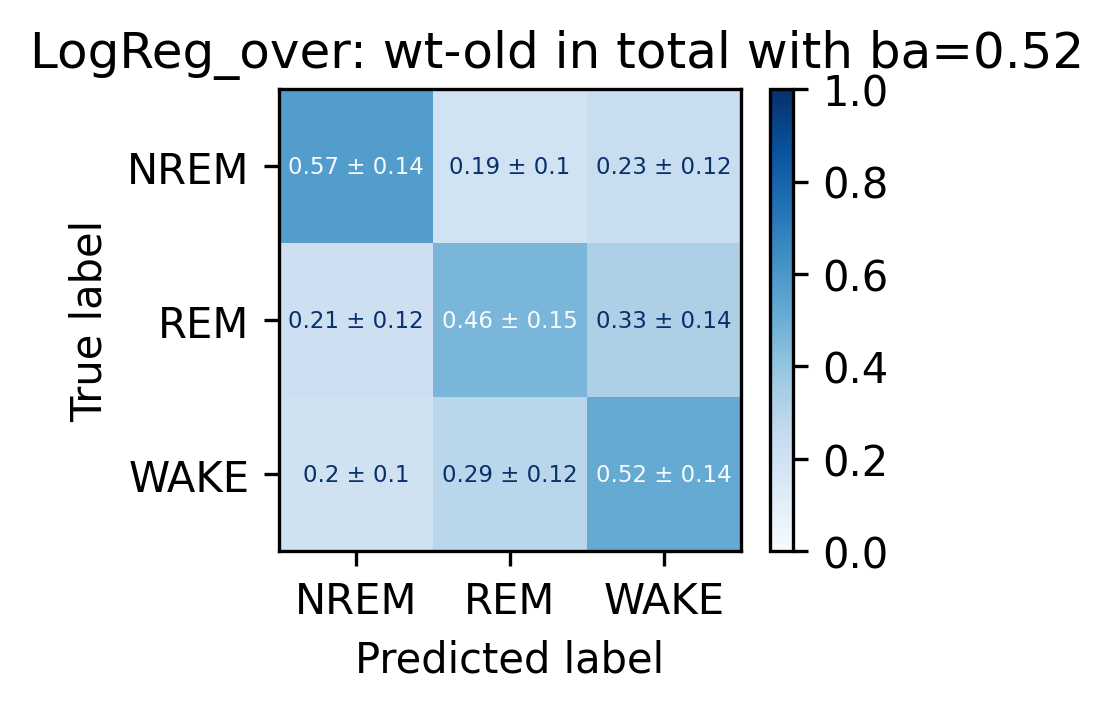

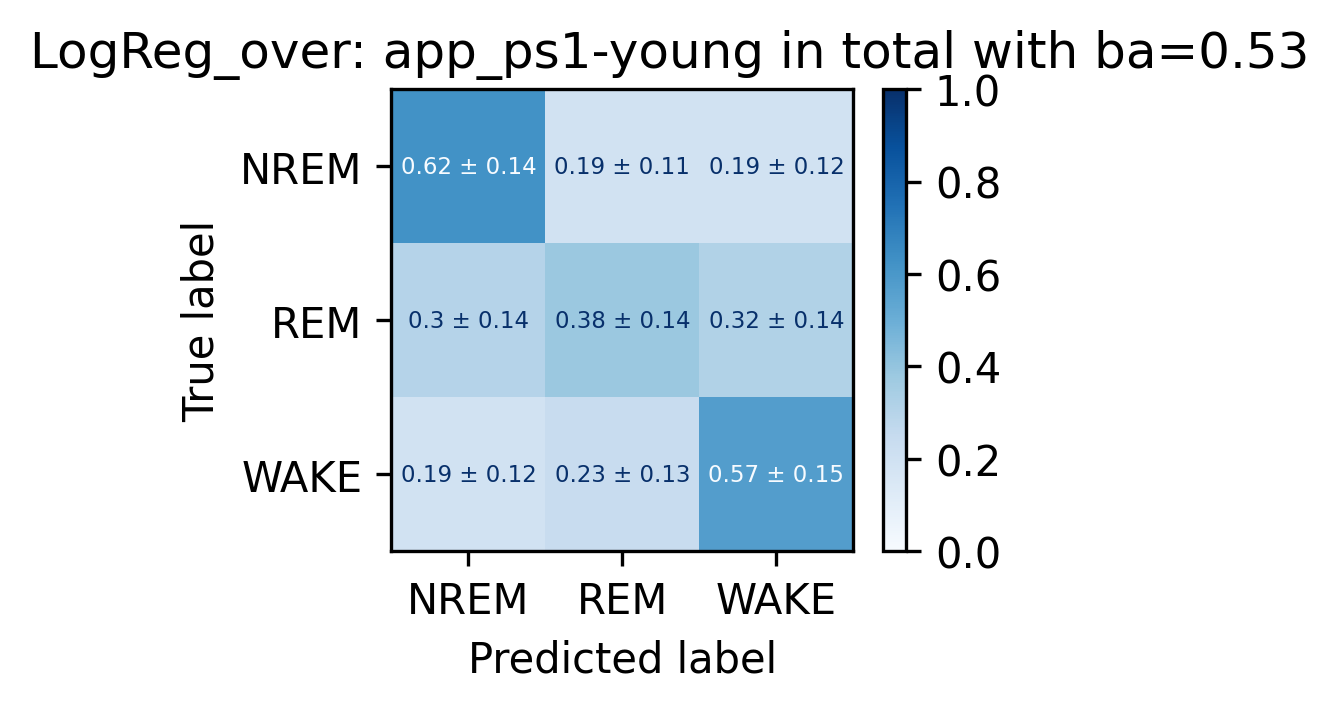

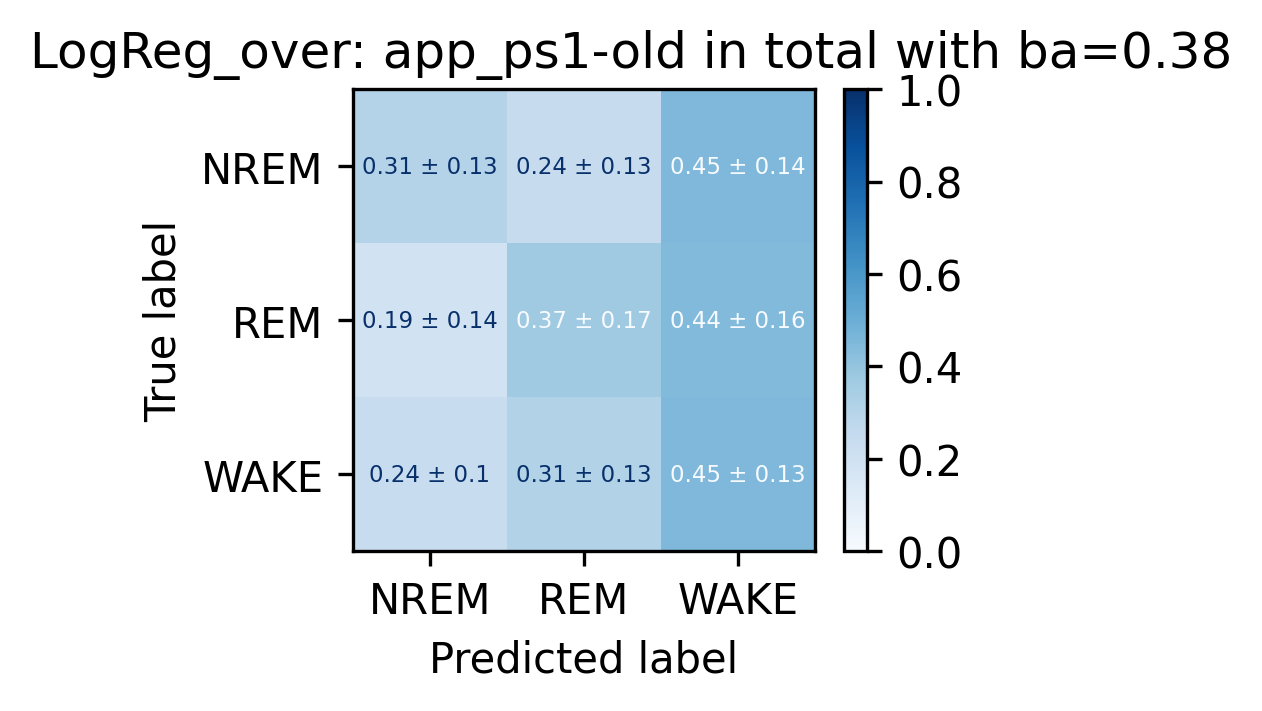

In [12]:
for key, val in cms.items():
    get_mean_cms_visual(val, graphic_train, key, by_geno=True, by_age=True, subplot_kwargs={'figsize':(2.5,2), 'dpi':300}, 
                        alt_se=True, addon_text=False, addon_suff='poster', parent_file_p='', savefig=False, file_format='pdf',
                       text_kw={'fontsize':5.5})

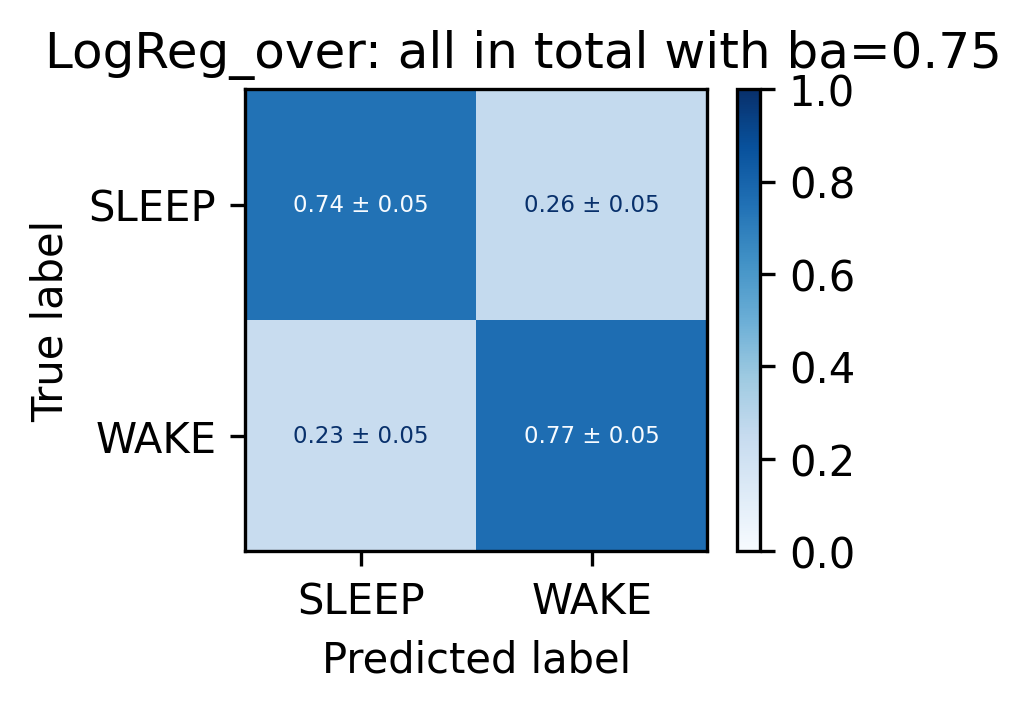

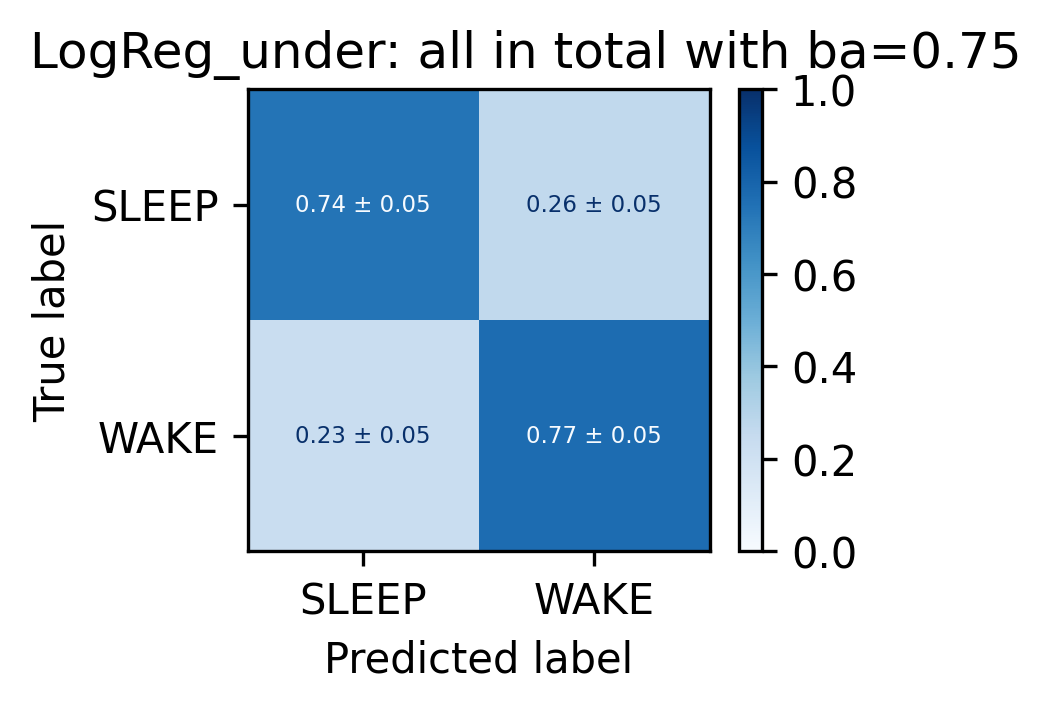

In [34]:
for key, val in sw_cms.items():
    get_mean_cms_visual(val, graphic_train, key, by_geno=False, by_age=False, subplot_kwargs={'figsize':(2.5,2), 'dpi':300}, 
                        alt_se=True, addon_text=False, addon_suff='poster_sw', parent_file_p='', savefig=True,
                       text_kw={'fontsize':5.5}, norm_size=2)

Datapoints per: 4315, 4315, 4315, 4315
0.0 111.57196572124323
0.0 106.11876690659527
1.5856423718594775e-284 38.91706007430124
0.0 87.94103571493076


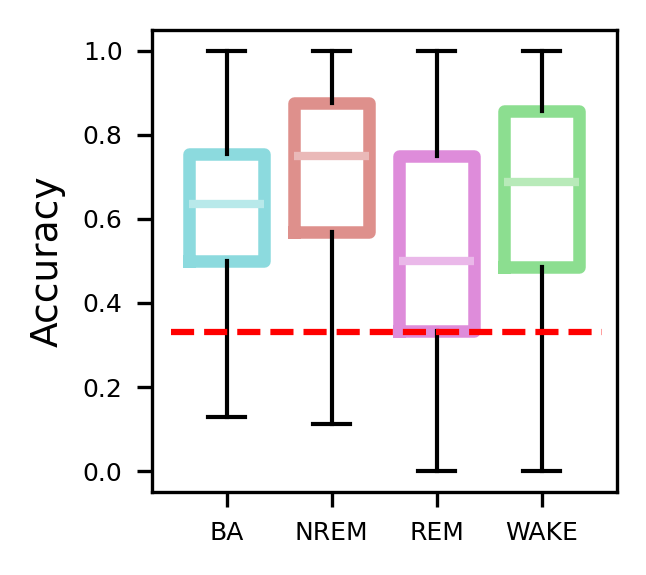

In [33]:
fig, ax = plt.subplots(1,1, figsize=(2,2), dpi=300)
stats, (_, pos) = diff_breakdown_box(cms['LogReg_over'], graphic_train, inner_d2=False, gap_between_groups=0.7, box_widths=0.5,ax=ax,
                  showfliers=False)
for group in stats:
    s = stats[group]
    for res in s:
        print(res.pvalue, res.statistic)
plt.ylabel("Accuracy", fontsize=9)
plt.xlabel("")
ax.tick_params(axis='both', which='major', labelsize=6)
#ax.tick_params(axis='both', which='minor', labelsize=8)
plt.hlines(0.33, 0.63, 3.5, color='r', linestyle='--')
# begin = '/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/'
# filename = f'{begin}poster/all/box_sleep_cond_3.svg'
# print(filename)
# fig.savefig(filename,bbox_inches="tight")

NameError: name 'sw_cms' is not defined

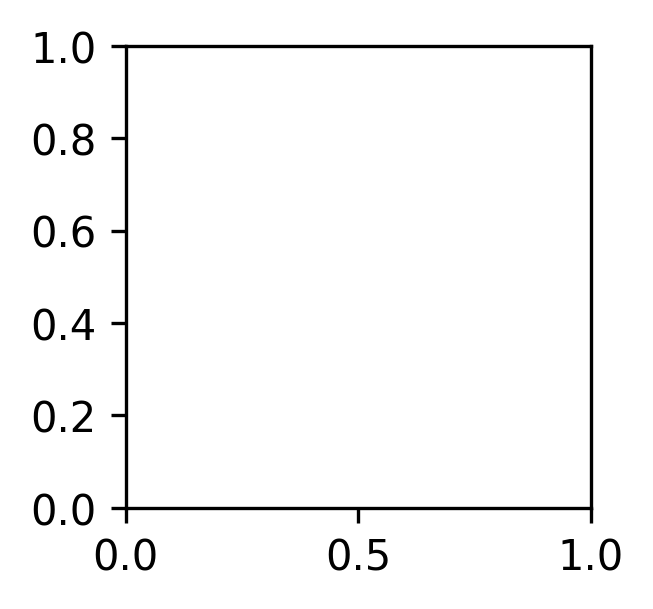

In [7]:
fig, ax = plt.subplots(1,1, figsize=(2,2), dpi=300)
stats, (_, pos) = diff_breakdown_box(sw_cms['LogReg_over'], graphic_train, inner_d2=False, gap_between_groups=0.7, box_widths=0.5,ax=ax,
                  showfliers=False, norm_size=2, labs=['BA', "SLEEP", "WAKE"])
for group in stats:
    s = stats[group]
    for res in s:
        print(res.pvalue, res.statistic)
plt.ylabel("Accuracy", fontsize=9)
plt.xlabel("")
ax.tick_params(axis='both', which='major', labelsize=6)
#ax.tick_params(axis='both', which='minor', labelsize=8)
plt.hlines(0.5, pos[0][0]-0.35, pos[-1][-1]+0.38, color='r', linestyle='--')
begin = '/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/'
# filename = f'{begin}poster_sw/all/box_sleep_cond_2.pdf'
# print(filename)
# fig.savefig(filename,bbox_inches="tight")

Datapoints per: 1015, 1015, 1015
Datapoints per: 1111, 1111, 1111
Datapoints per: 956, 956, 956
Datapoints per: 1235, 1235, 1235


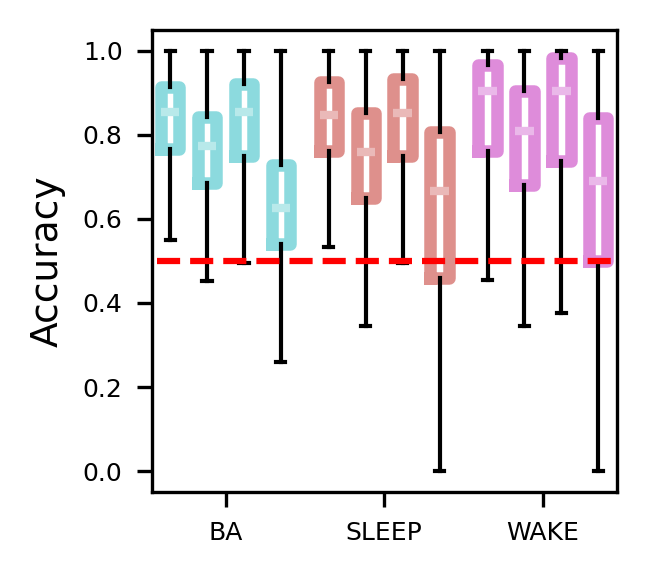

In [21]:
fig, ax = plt.subplots(1,1, figsize=(2,2), dpi=300)
_, pos = diff_breakdown_box(sw_cms['LogReg_over'], graphic_train, inner_d2=False, gap_between_groups=1.3, box_widths=0.5,
                            color_by_group=True, ax=ax, gap_between_cols=1,
                  showfliers=False, norm_size=2, labs=['BA', "SLEEP", "WAKE"], grouping_vars={"by_age":True, "by_geno":True})
plt.ylabel("Accuracy", fontsize=9)
plt.xlabel("")
ax.tick_params(axis='both', which='major', labelsize=6)
#ax.tick_params(axis='both', which='minor', labelsize=8)
plt.hlines(0.5, pos[0][0]-0.35, pos[-1][-1]+0.38, color='r', linestyle='--')
# begin = '/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/'
# filename = f'{begin}poster_sw/all/box_sleep_cond_2.pdf'
# print(filename)
# fig.savefig(filename,bbox_inches="tight")

In [27]:
use, num_rem = remove_irregular_cm(cms['LogReg_over'])
#print(use)
merge_accuracy_neuron(use, graphic_train, name="68epochunfiltered", save=True)

{'caf69_358_1228_0_12_0_wt': array([[0.56451613, 0.43548387, 0.        ],
       [0.        , 0.6       , 0.4       ],
       [0.        , 0.01626016, 0.98373984]]), 'caf69_358_1228_0_12_1_wt': array([[0.66666667, 0.2       , 0.13333333],
       [0.        , 0.66666667, 0.33333333],
       [0.        , 0.03571429, 0.96428571]]), 'caf69_358_1228_0_12_2_wt': array([[0.66666667, 0.26666667, 0.06666667],
       [0.22222222, 0.33333333, 0.44444444],
       [0.        , 0.        , 1.        ]]), 'caf69_358_1228_0_12_3_wt': array([[1.        , 0.        , 0.        ],
       [0.        , 0.88888889, 0.11111111],
       [0.        , 0.01886792, 0.98113208]]), 'caf69_358_1228_0_12_4_wt': array([[0.73333333, 0.2       , 0.06666667],
       [0.11111111, 0.77777778, 0.11111111],
       [0.        , 0.        , 1.        ]]), 'caf69_358_1228_0_12_5_wt': array([[1.        , 0.        , 0.        ],
       [0.        , 0.77777778, 0.22222222],
       [0.        , 0.05      , 0.95      ]]), 'caf69_35

         index region                        cell  animal celltype geno  \
1          414   ACad    caf69_358_1228_0_12_0_wt   caf69      RSU   wt   
4          657   ACad    caf69_358_1228_0_12_1_wt   caf69      RSU   wt   
7          847   ACad    caf69_358_1228_0_12_2_wt   caf69      RSU   wt   
10        1107   ACad    caf69_358_1228_0_12_3_wt   caf69      RSU   wt   
13        1361   ACad    caf69_358_1228_0_12_4_wt   caf69      RSU   wt   
...        ...    ...                         ...     ...      ...  ...   
12936  1787525     V1  bth100_99_0624_12_24_90_wt  bth100      RSU   wt   
12939  1787996     V1  bth100_99_0624_12_24_91_wt  bth100      RSU   wt   
12942  1788356     V1  bth100_99_0624_12_24_92_wt  bth100      RSU   wt   
12945  1789623     V1  bth100_99_0624_12_24_93_wt  bth100       FS   wt   
12948  1791053     V1  bth100_99_0624_12_24_94_wt  bth100      RSU   wt   

      cell_no  age age_group  state_chunks_nrem  state_chunks_rem  \
1           0  358       old  

,index,region,cell,animal,celltype,geno,cell_no,age,age_group,state_chunks_nrem,state_chunks_rem,state_chunks_wake,balanced_acc,nrem_acc,rem_acc,wake_acc
1,414,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,137,40,414,0.716085,0.564516,0.600000,0.983740
4,657,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,44,28,66,0.765873,0.666667,0.666667,0.964286
7,847,ACad,caf69_358_1228_0_12_2_wt,caf69,RSU,wt,2,358,old,48,31,118,0.666667,0.666667,0.333333,1.000000
10,1107,ACad,caf69_358_1228_0_12_3_wt,caf69,RSU,wt,3,358,old,49,31,181,0.956674,1.000000,0.888889,0.981132
13,1361,ACad,caf69_358_1228_0_12_4_wt,caf69,RSU,wt,4,358,old,47,31,174,0.837037,0.733333,0.777778,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12936,1787525,V1,bth100_99_0624_12_24_90_wt,bth100,RSU,wt,90,99,young,54,18,220,0.738693,0.769231,0.600000,0.846847
12939,1787996,V1,bth100_99_0624_12_24_91_wt,bth100,RSU,wt,91,99,young,139,22,399,0.624230,0.724138,0.250000,0.898551
12942,1788356,V1,bth100_99_0624_12_24_92_wt,bth100,RSU,wt,92,99,young,92,18,199,0.497562,0.645161,0.600000,0.247525
12945,1789623,V1,bth100_99_0624_12_24_93_wt,bth100,FS,wt,93,99,young,528,84,1157,0.417504,0.516340,0.571429,0.164745


Datapoints per: 251, 327, 243, 290
Datapoints per: 354, 227, 302, 352
1.945315018993303e-55 -17.644871970061885
4.820410569788717e-16 -8.471929357539965
1.329860347820073e-13 -7.597795857087833
1.186709907258282e-43 -14.974368273796449
/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/poster/all/box_region.pdf


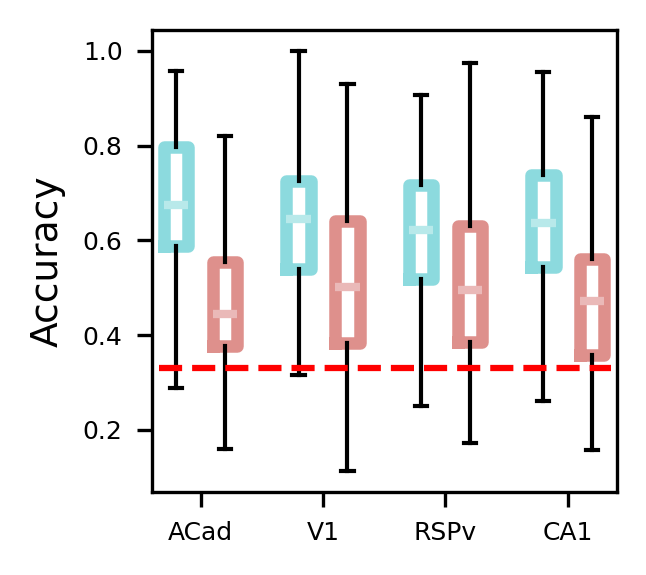

In [14]:
fig, ax = plt.subplots(1,1, figsize=(2,2), dpi=300)
stats, (_, pos) = diff_breakdown_box_region(cms['LogReg_over'], graphic_train, inner_d2=False, 
                                            gap_between_groups=1.5, box_widths=0.5,ax=ax, color_by_group=False,
                  showfliers=False,)
for group in stats:
    s = stats[group]
    for res in s:
        print(res.pvalue, res.statistic)
plt.ylabel("Accuracy", fontsize=9)
plt.xlabel("")
ax.tick_params(axis='both', which='major', labelsize=6)
#ax.tick_params(axis='both', which='minor', labelsize=8)
plt.hlines(0.33, pos[0][0]-0.35, pos[-1][-1]+0.38, color='r', linestyle='--')
begin = '/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/'
filename = f'{begin}poster/all/box_region.pdf'
print(filename)
fig.savefig(filename,bbox_inches="tight")

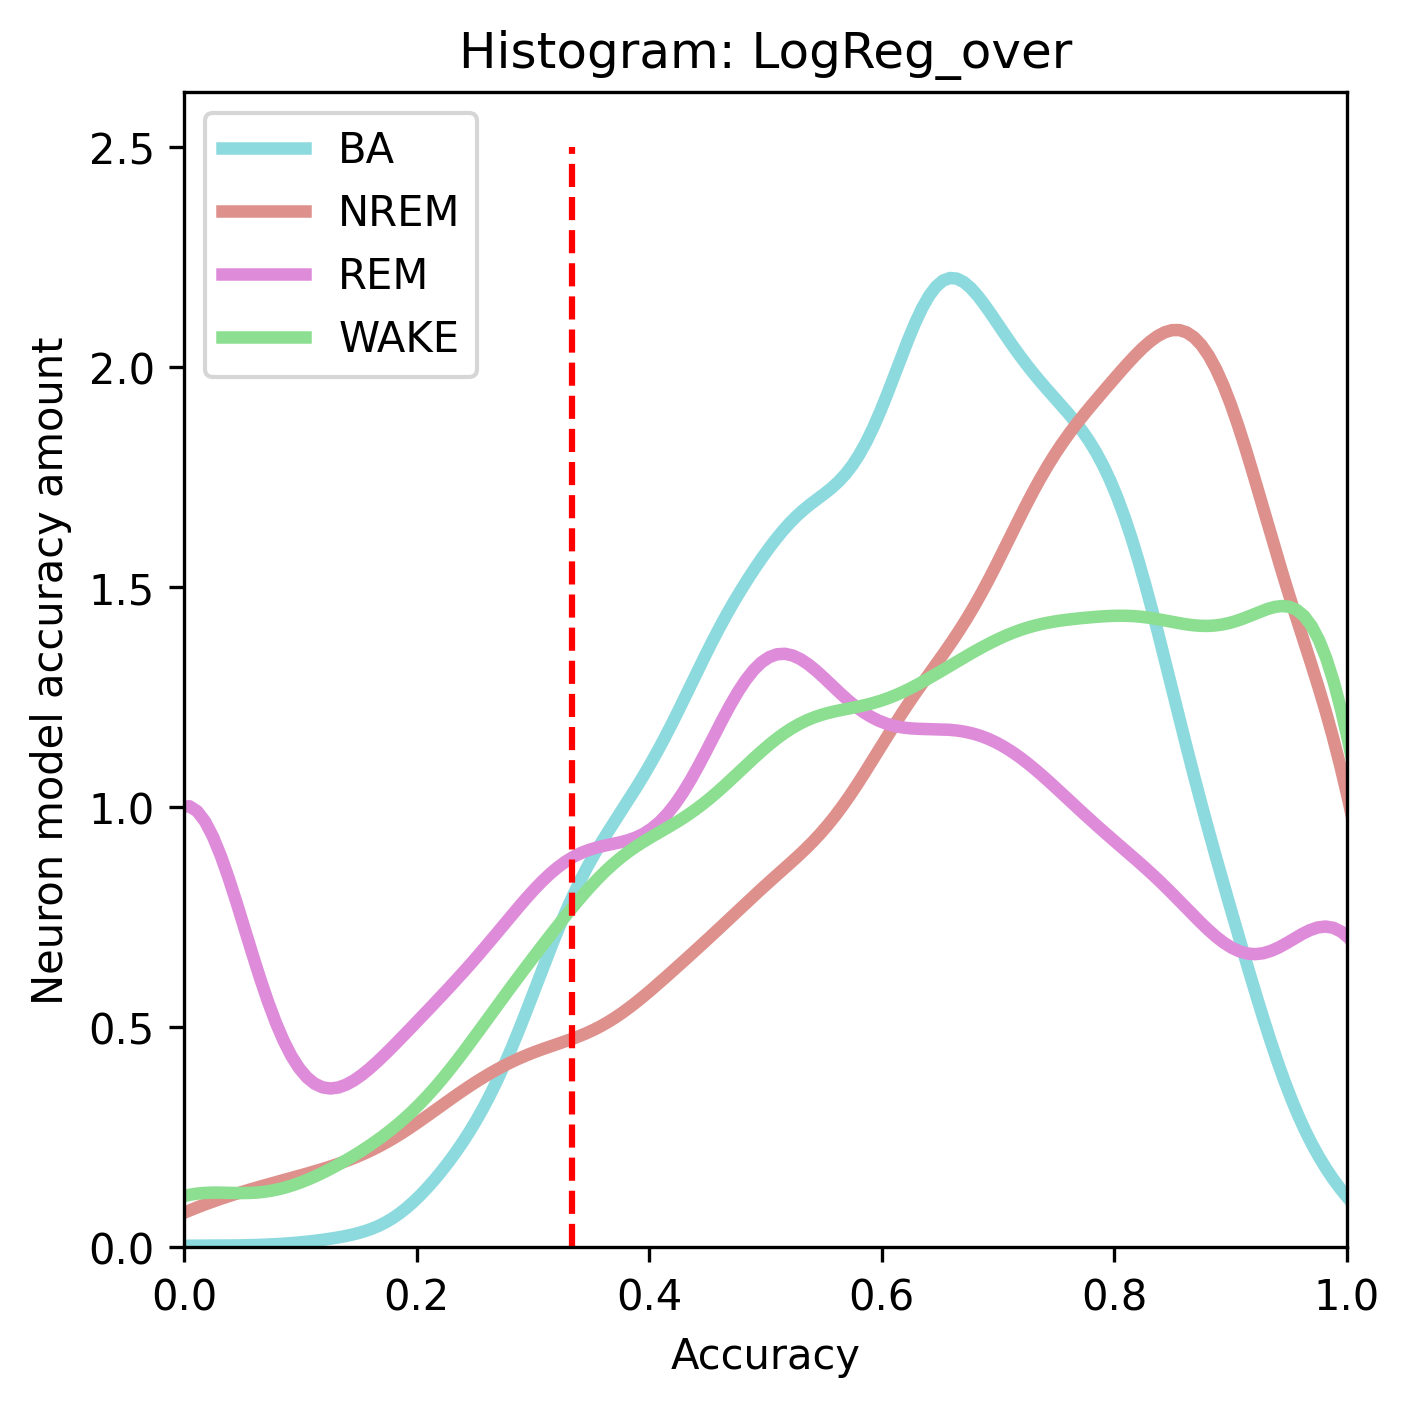

/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/poster/all/Histogram: LogReg_over.pdf


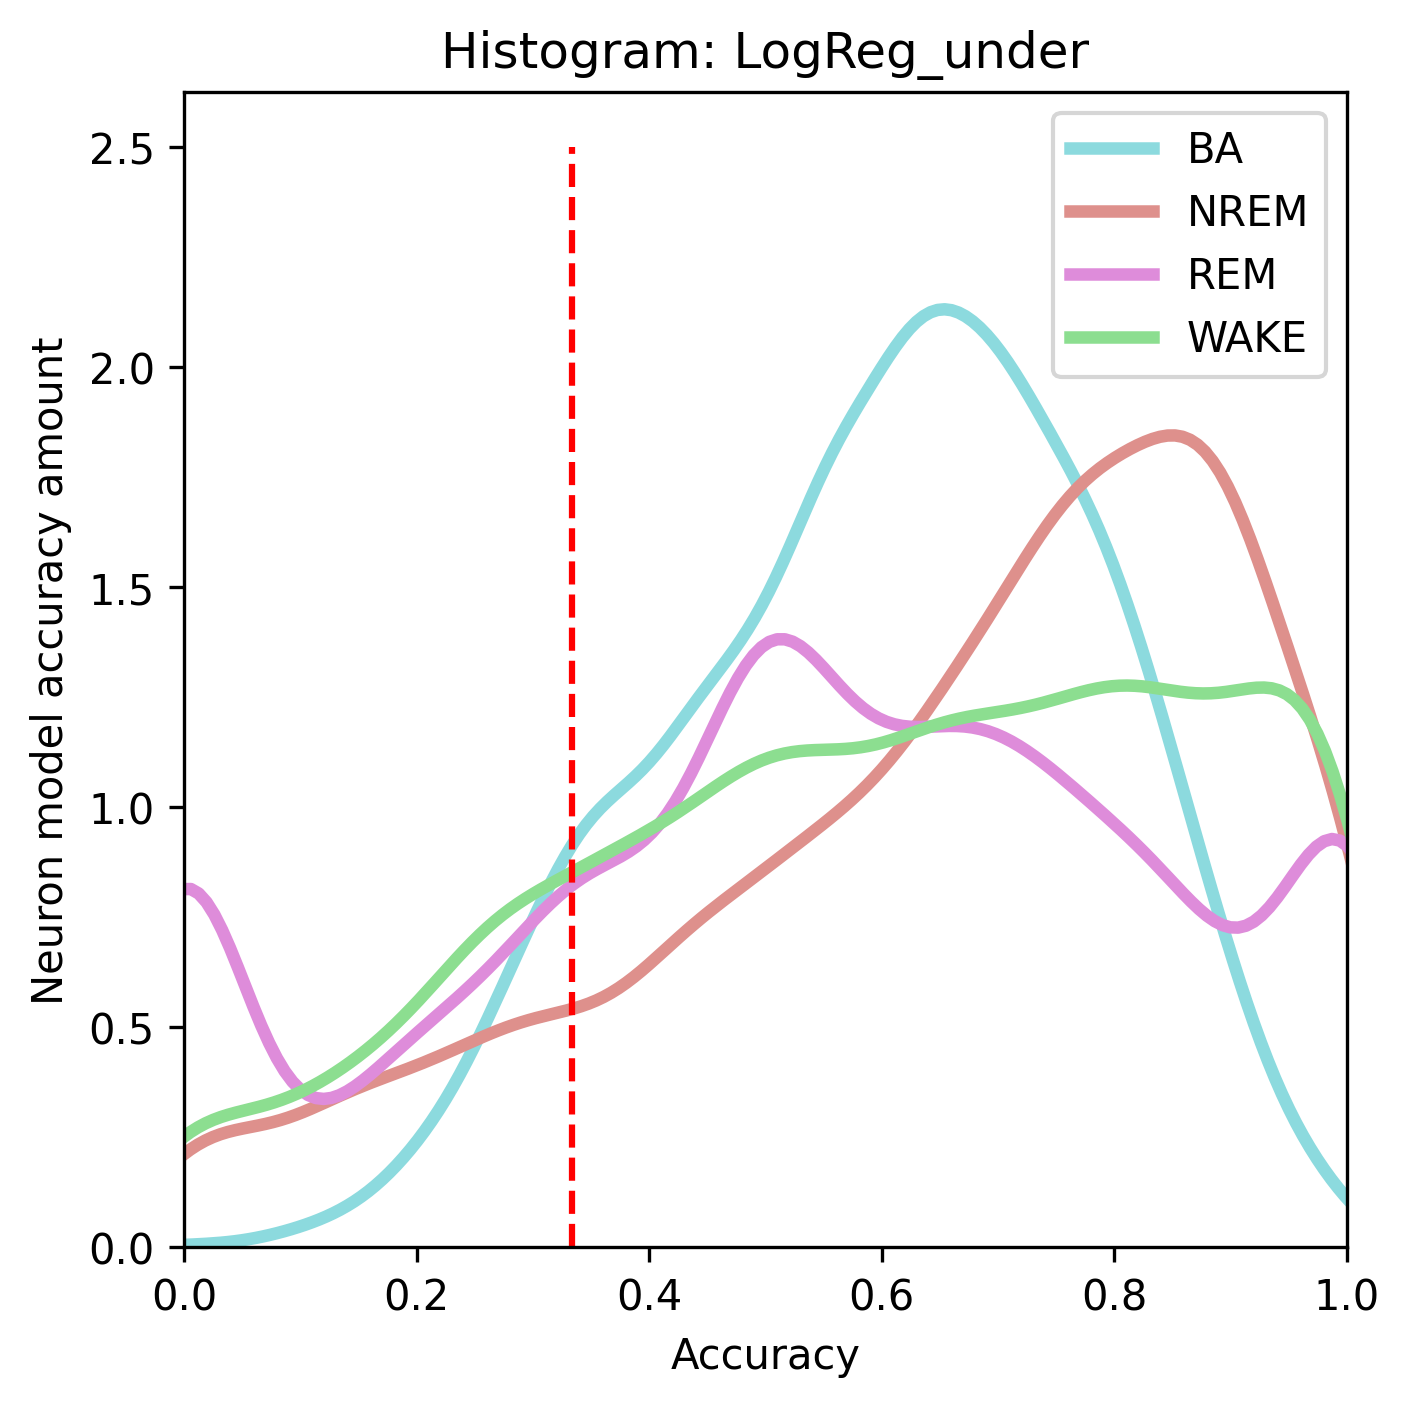

/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/poster/all/Histogram: LogReg_under.pdf


In [9]:
plot_evs = [accuracy, lambda x:x[0][0], lambda x:x[1][1], lambda x:x[2][2]]
for key, val in cms.items():
    fig, ax = plt.subplots(1,1, figsize=(5,5), dpi=300)
    cm_label = f"Histogram: {key}"
    get_cm_distrib_hist(val, graphic_train, cm_label, plot_eval=plot_evs, histtype='bar', linewidth=3, kde=True)
    plt.legend(("BA", "NREM", "REM", "WAKE"))
    plt.vlines(1/3, 0, 2.5, color='r', ls='--')
    plt.xlim(0,1)
    plt.show()
    begin = '/media/HlabShare/Toby_work/sleep_indiv_neuron/Figures/'
    filename = f'{begin}poster/all/{cm_label}.pdf'
    print(filename)
    fig.savefig(filename,bbox_inches="tight")

In [76]:
ecf_plot(train_scaled, split=True)

KeyError: 'sleep_state'

Datapoints per: 21463, 6876, 6876
Datapoints per: 26475, 10330, 10330
Datapoints per: 37948, 13941, 13941
Datapoints per: 25601, 22864, 22864


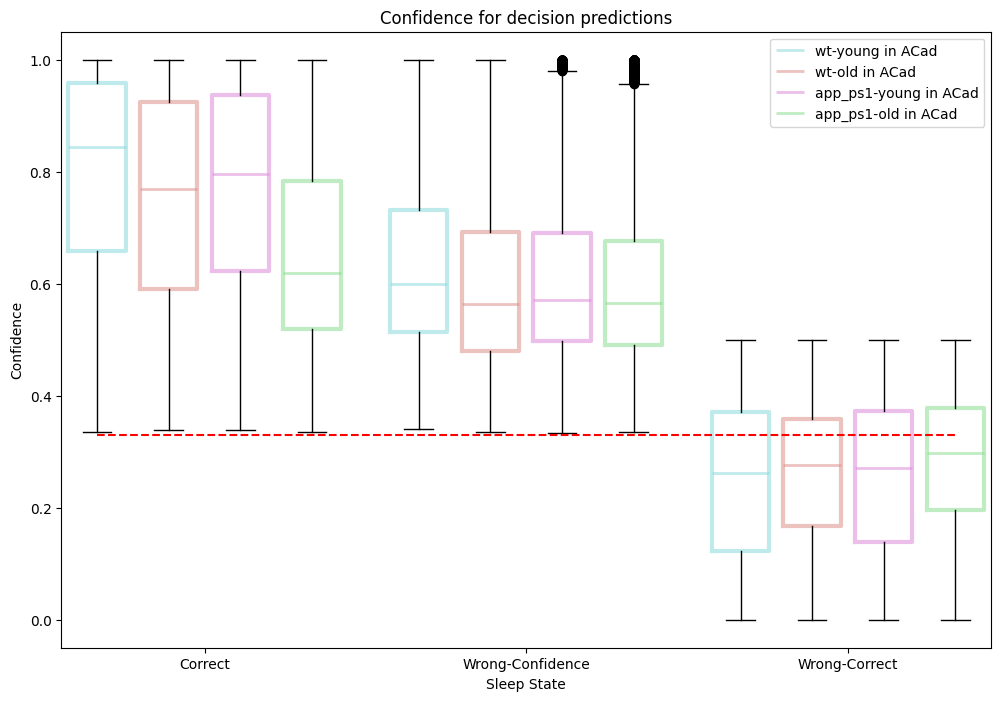

Datapoints per: 24804, 9278, 9278
Datapoints per: 33704, 20263, 20263
Datapoints per: 27251, 10227, 10227
Datapoints per: 13460, 11814, 11814


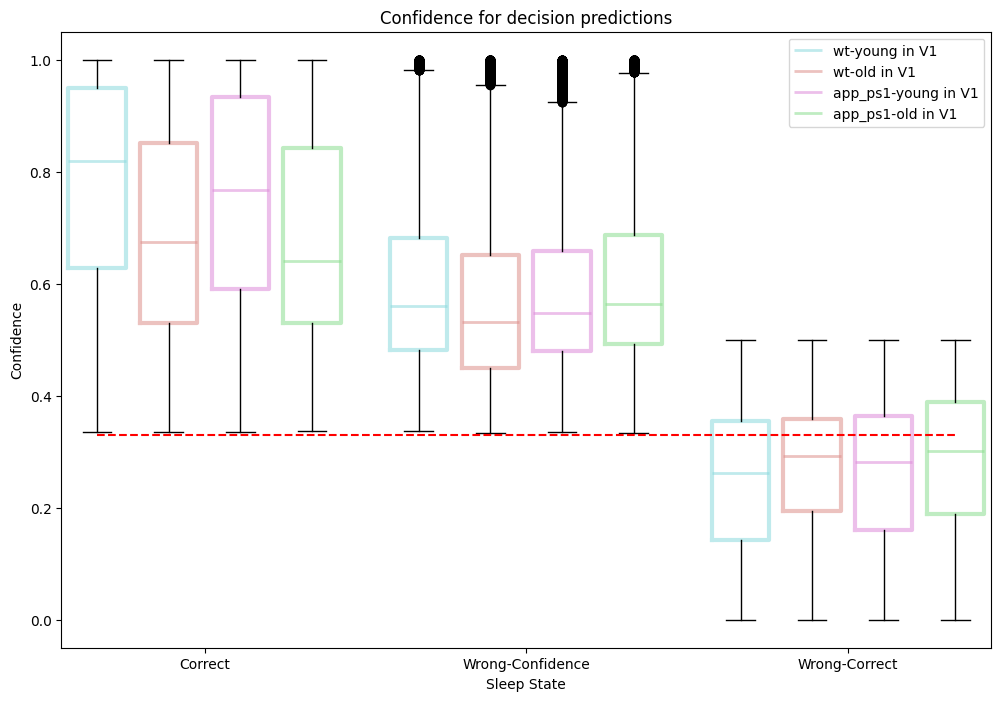

zbr106_101_0223_0_12_28_wt don't have a model :(
Datapoints per: 27079, 9584, 9584
Datapoints per: 31924, 14901, 14901
Datapoints per: 24488, 9110, 9110
Datapoints per: 24150, 21223, 21223


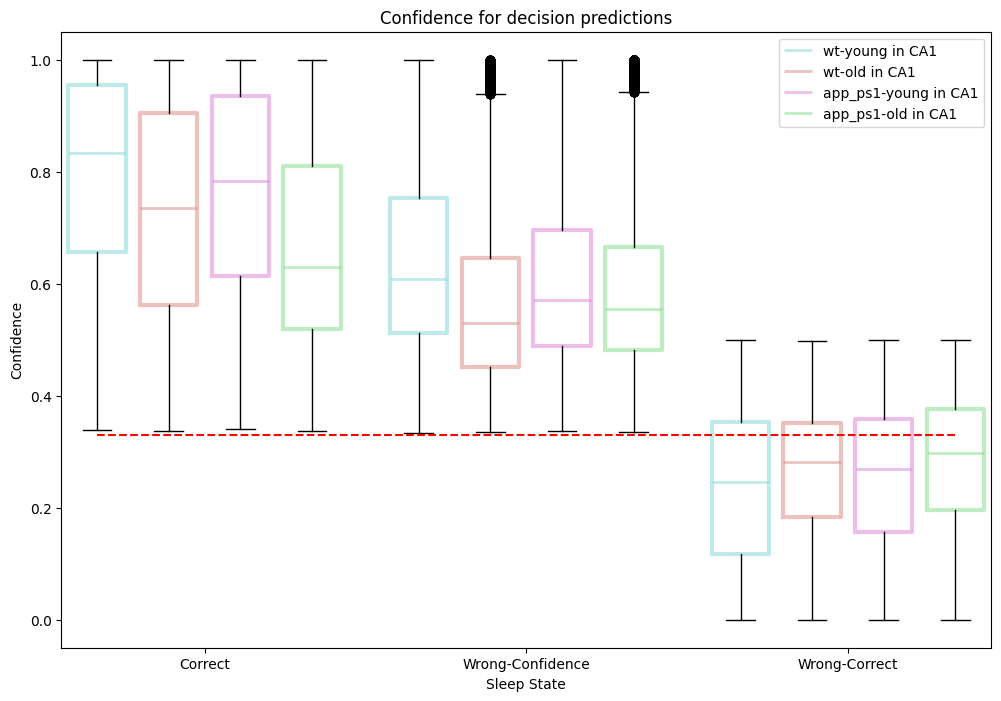

Datapoints per: 17029, 6029, 6029
Datapoints per: 29705, 18758, 18758
Datapoints per: 25536, 9784, 9784
Datapoints per: 22842, 16253, 16253


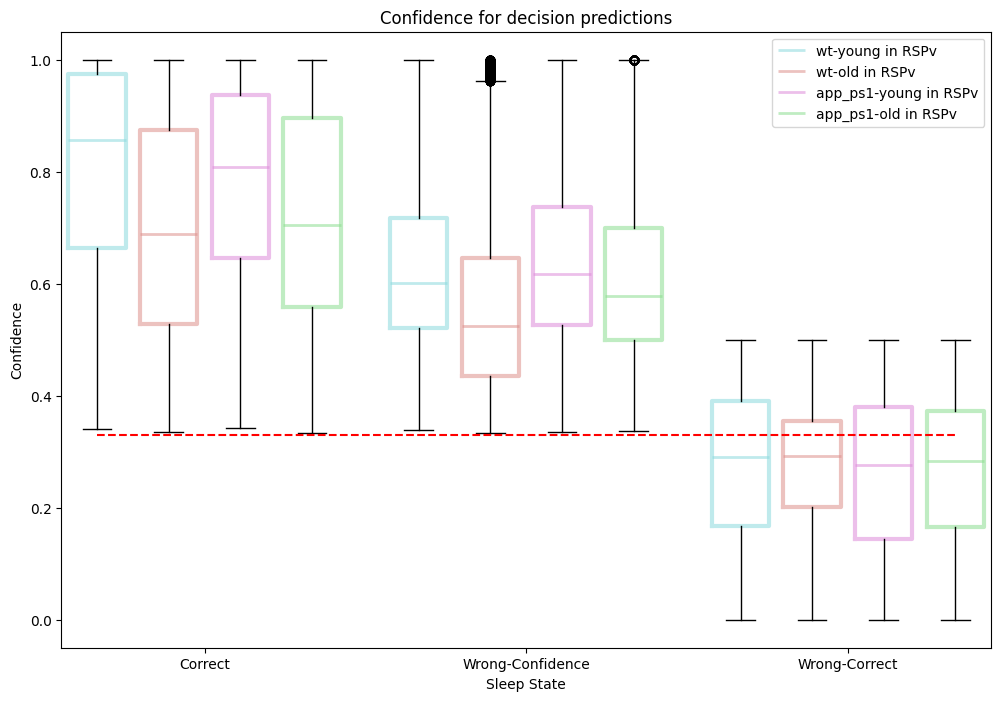

In [9]:
for region in ['ACad', 'V1', 'CA1', "RSPv"]:
    overall_arr, labels,_ = accuracy_breakdown(graphic_train, basic_log_cms['LogReg_over'], 
                                     by_region=True, by_geno=True, by_age=True, subset={'region':region})
    use_arr = []
    for arr in overall_arr:
        use_arr.append([arr[0], arr[2], arr[3]])
    bits,poses = box_whisker(*use_arr,
                             inner_d2=False, color_by_group=False, labels=['Correct', 'Wrong-Confidence', 'Wrong-Correct'],
                            box_colors = [ext_colors], median_colors=[ext_colors])
    plt.legend([bit['medians'][0] for bit in bits], labels)
    plt.title("Confidence for decision predictions")
    plt.ylabel("Confidence")
    plt.hlines(0.33, poses[0][0], poses[-1][-1], color='r', linestyle='--')
    plt.show()

zbr106_101_0223_0_12_28_wt don't have a model :(


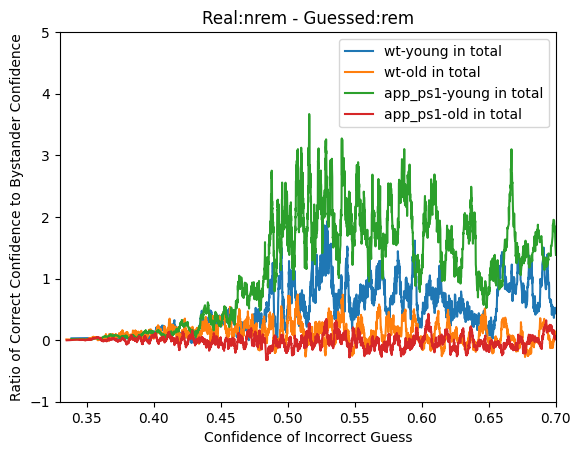

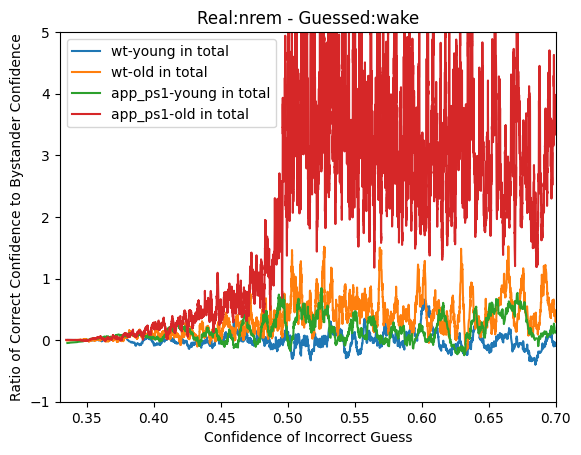

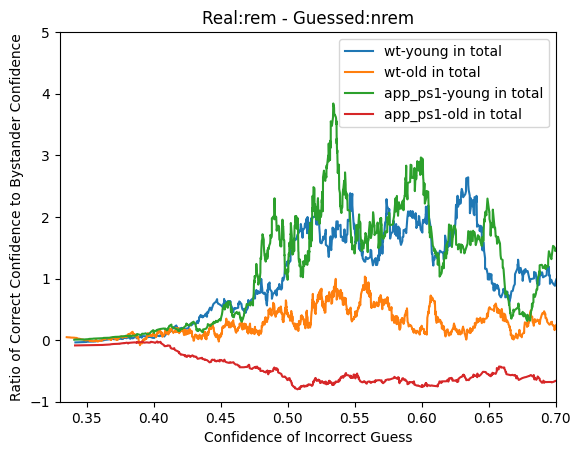

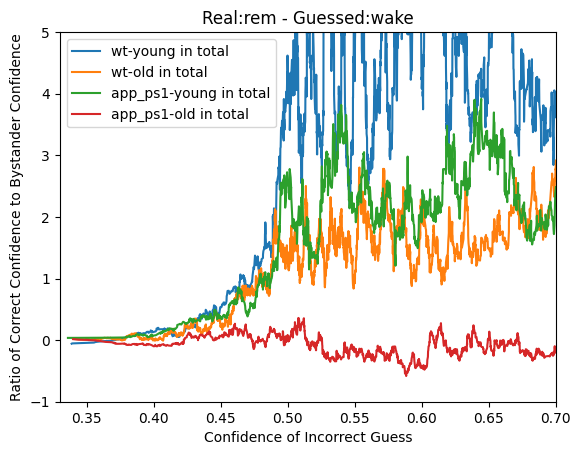

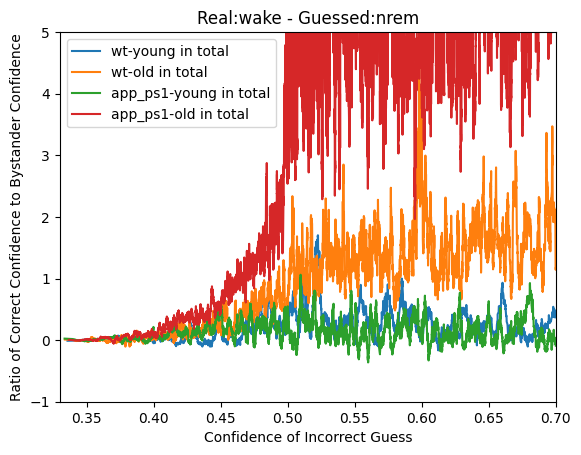

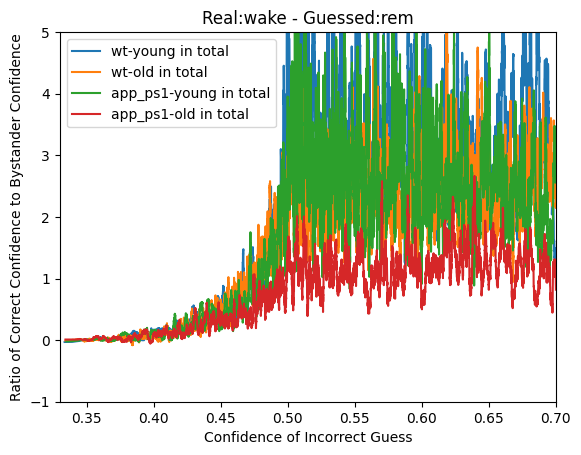

In [18]:
wrong_confidence_breakdown_by_state(graphic_train, basic_log_cms['LogReg_over'])

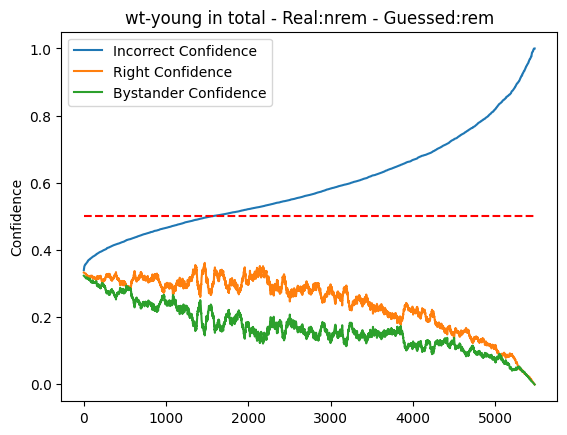

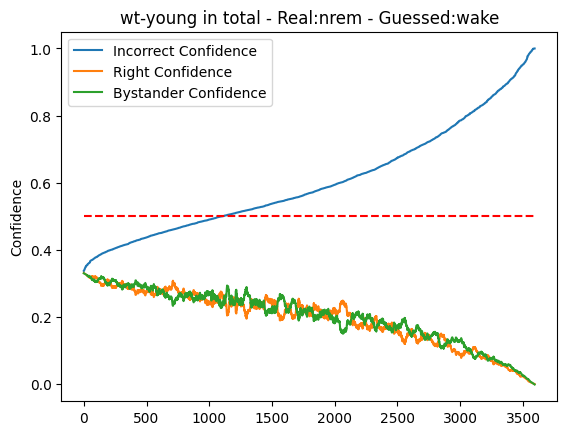

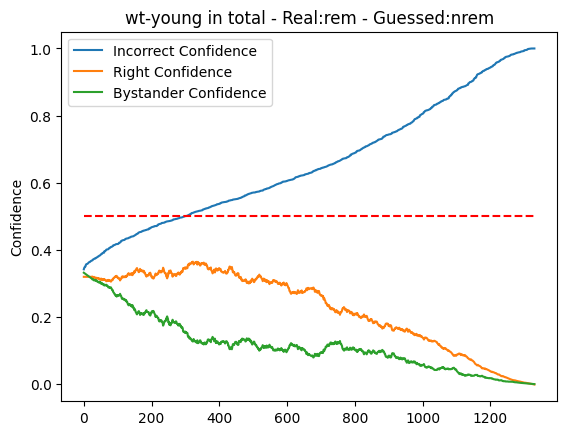

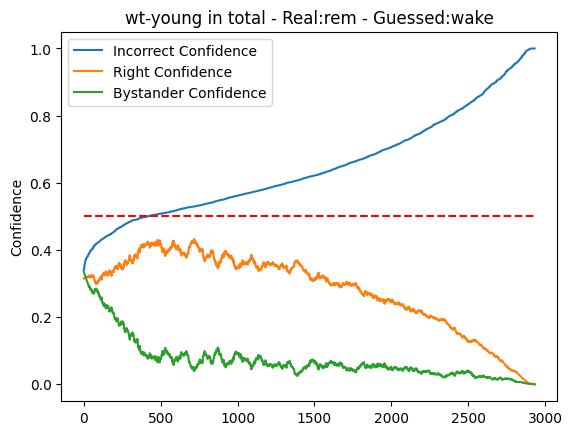

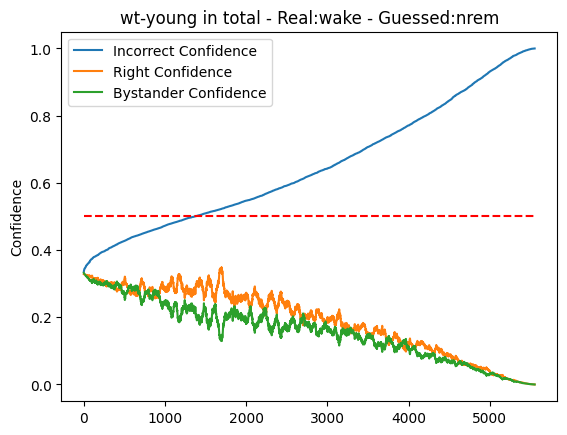

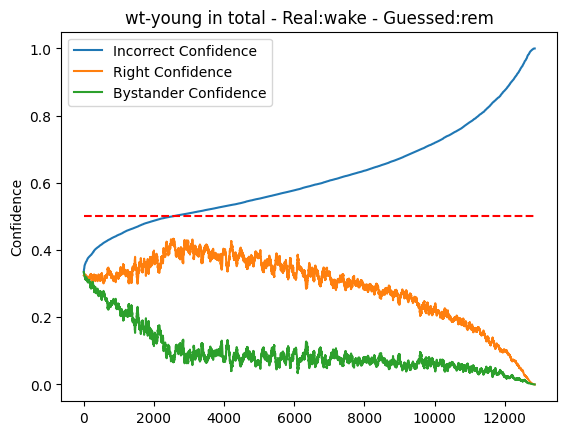

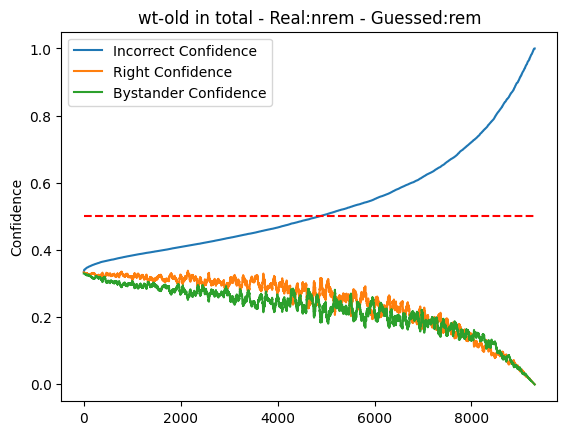

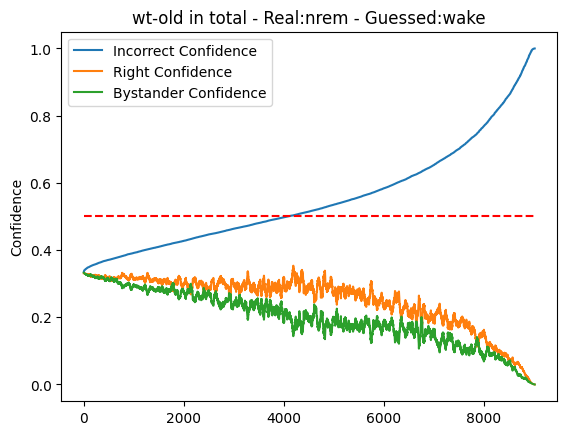

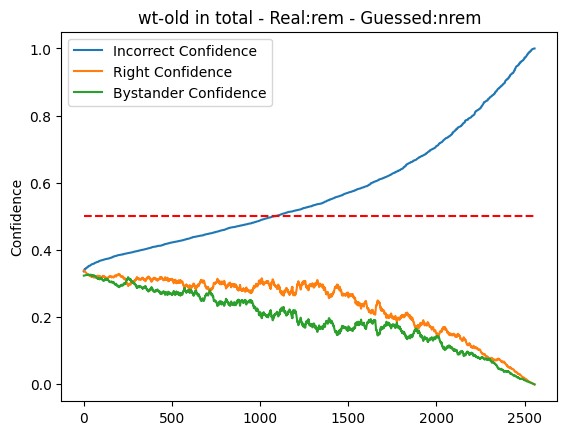

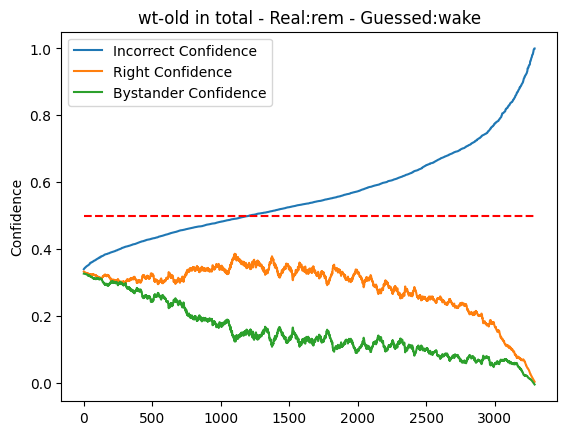

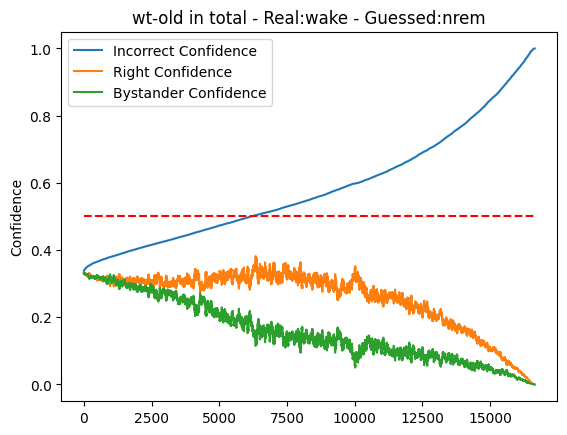

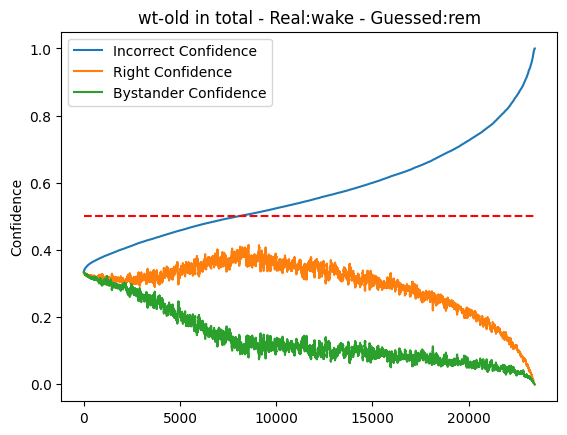

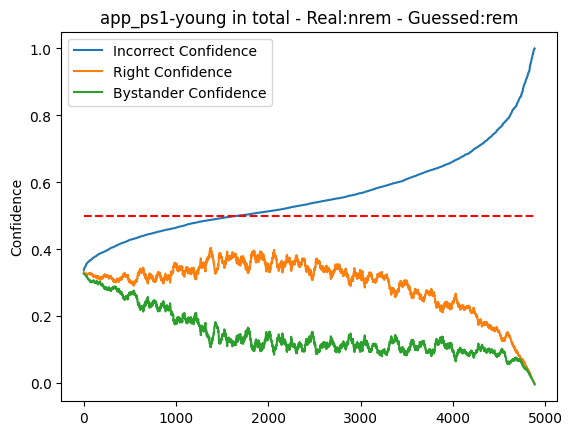

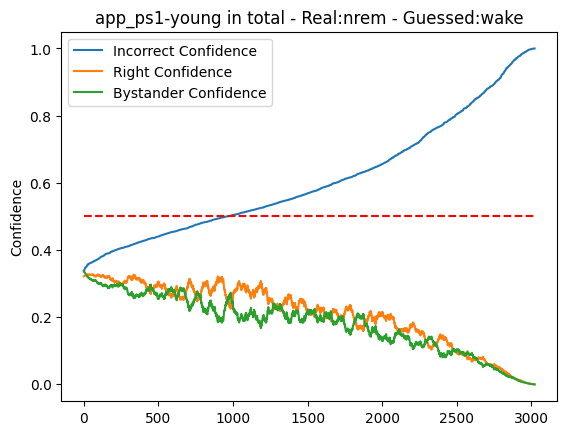

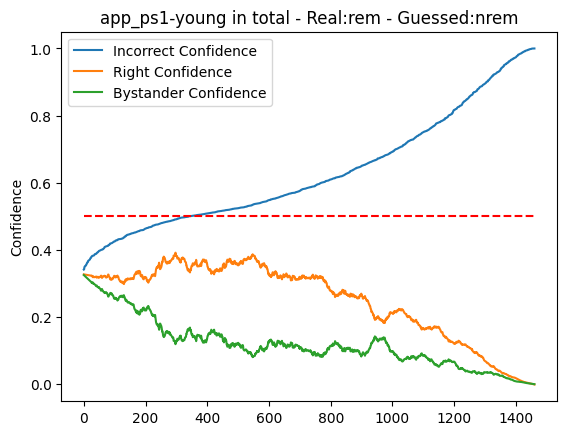

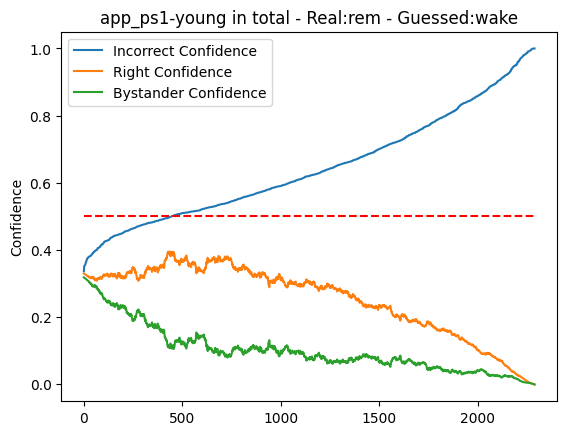

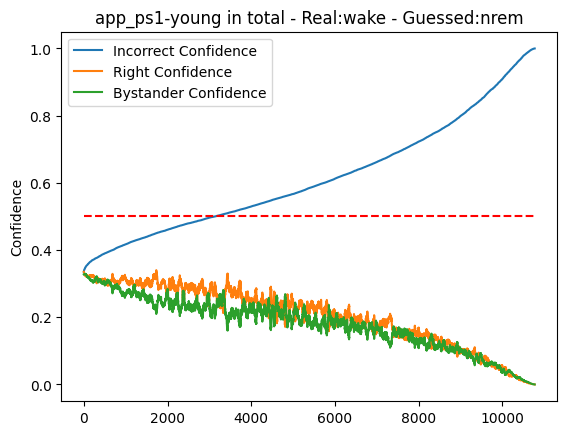

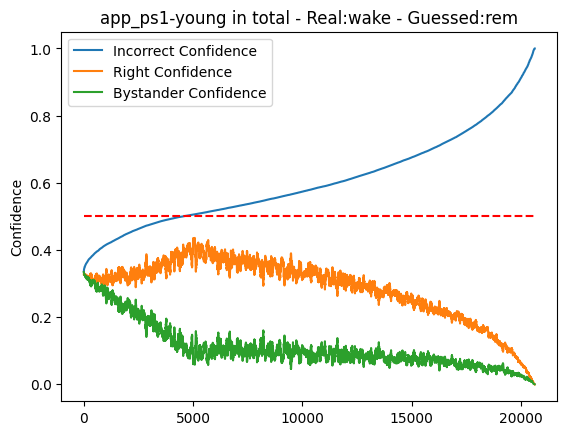

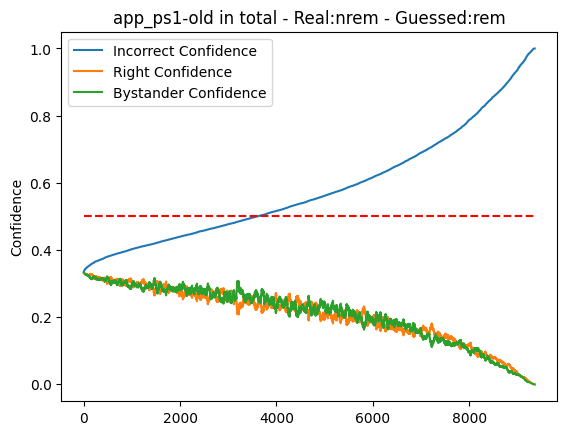

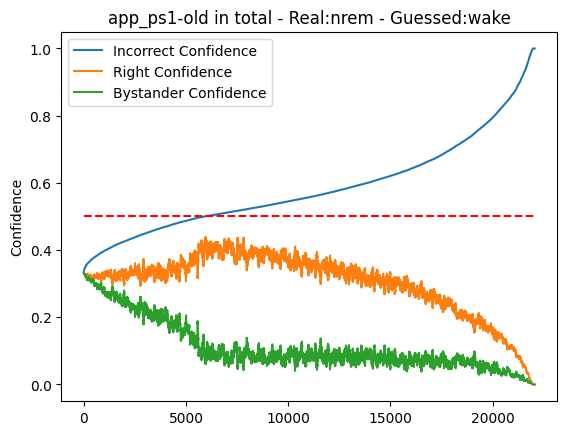

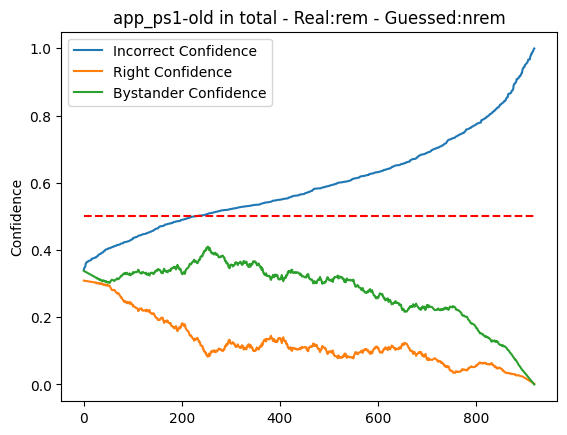

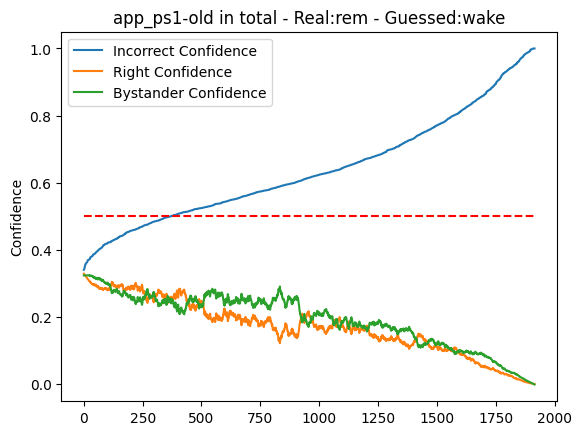

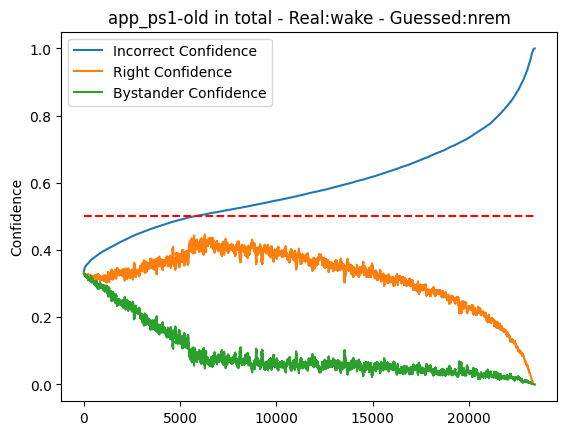

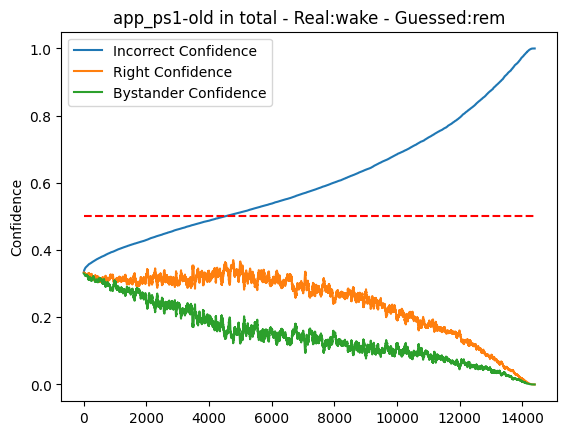

In [12]:
wrong_confidence_breakdown

zbr106_101_0223_0_12_28_wt don't have a model :(


,right_conf,wrong_conf,bystander_conf,corr_state,wrong_guess_state,close_ratio
0,0.333962,3.336146e-01,3.324236e-01,0,2,4.627043e-03
1,0.334455,3.315633e-01,3.339819e-01,2,1,1.415957e-03
2,0.335044,3.313541e-01,3.336021e-01,2,1,4.321706e-03
3,0.335081,3.312798e-01,3.336388e-01,0,2,4.323674e-03
4,0.335092,3.315508e-01,3.333573e-01,2,1,5.203670e-03
...,...,...,...,...,...,...
413266,1.000000,5.645067e-18,8.881784e-16,2,1,1.125900e+15
413267,1.000000,6.695993e-16,0.000000e+00,0,2,inf
413268,1.000000,1.052084e-23,4.440892e-16,2,1,2.251800e+15
413269,1.000000,1.209529e-16,1.110223e-16,2,1,9.007199e+15


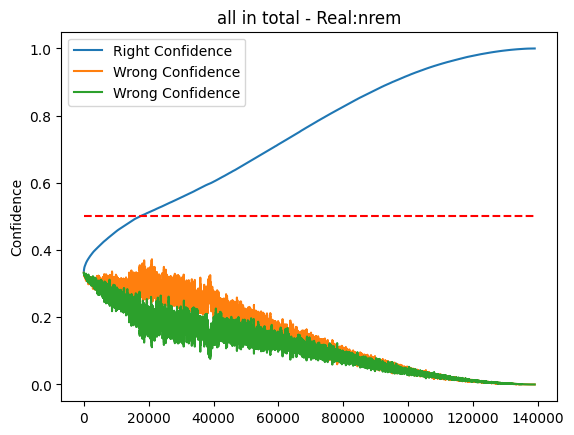

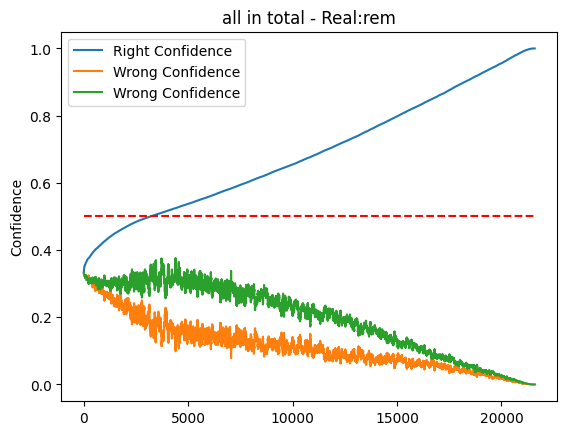

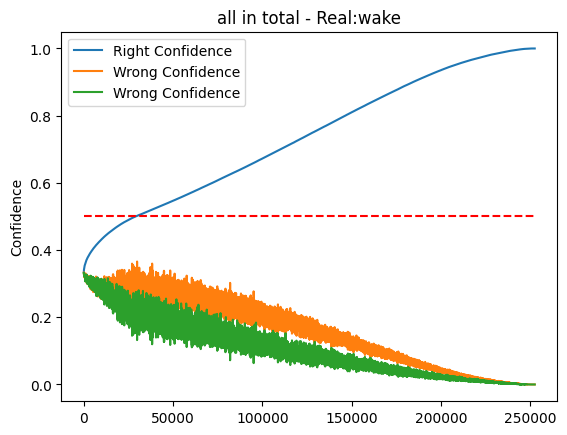

In [16]:
correct_confidence_breakdown_by_state(graphic_train, basic_log_cms['LogReg_over'])

In [133]:
coef = get_coef(basic_log_models['LogReg_over'])
spike_matrix = ['ifr', 'mean_isis', 'median_isis', 'max_isis', 'min_isis', 'sd', 'cv', 'cv2', 'lv', 'lvr']
state = ['NREM', 'REM', 'WAKE']
coefs_df = pd.DataFrame()
for cell, coef_array in coef.items():
    temp_df = pd.DataFrame(coef_array, columns=spike_matrix)
    temp_df['state'] = state
    temp_df['cell'] = cell
    coefs_df = pd.concat([coefs_df, temp_df])
# Reset index for a clean DataFrame
coefs_df.reset_index(drop=True, inplace=True)

wt-young in total


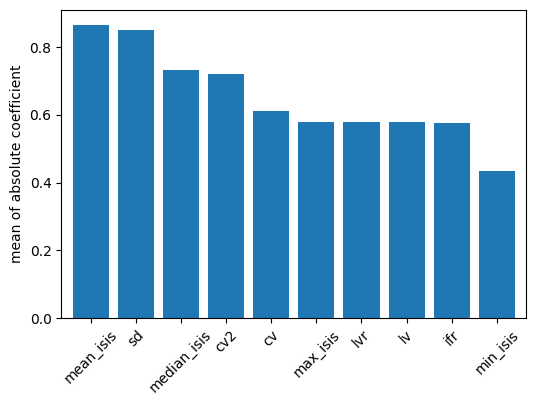

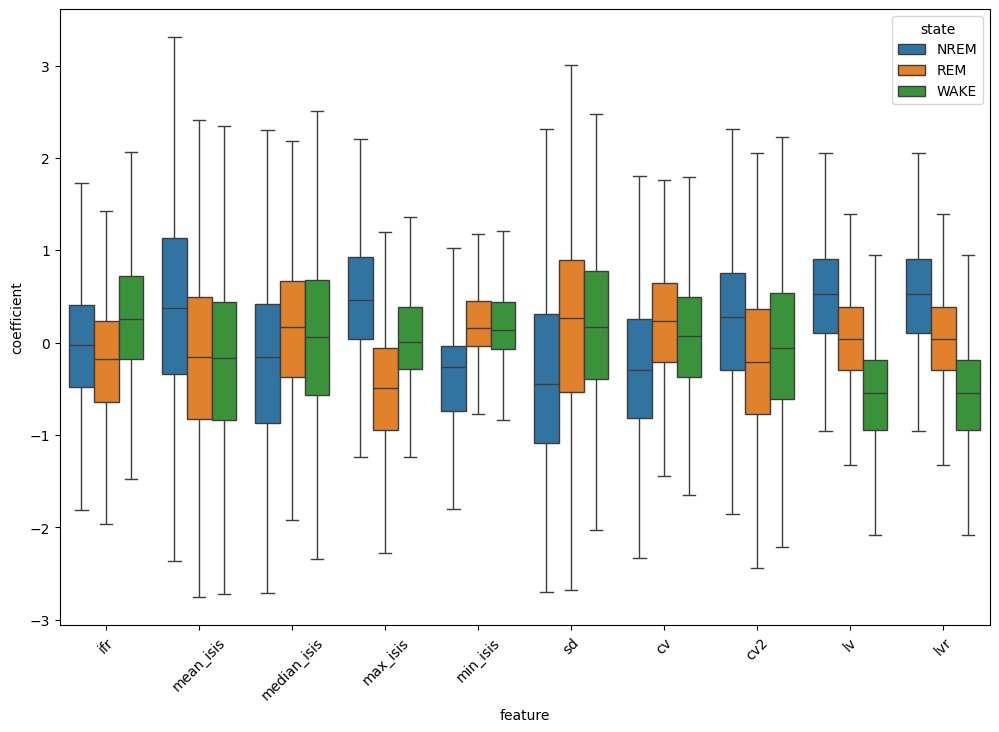

wt-old in total


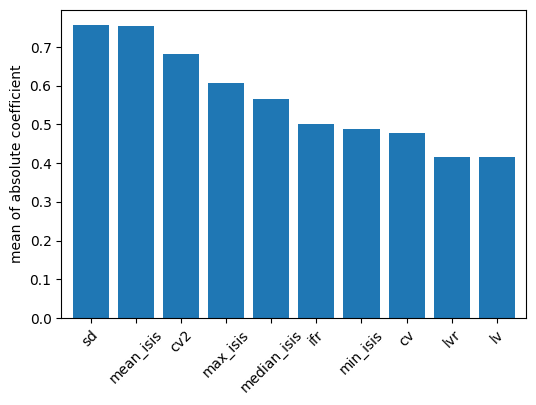

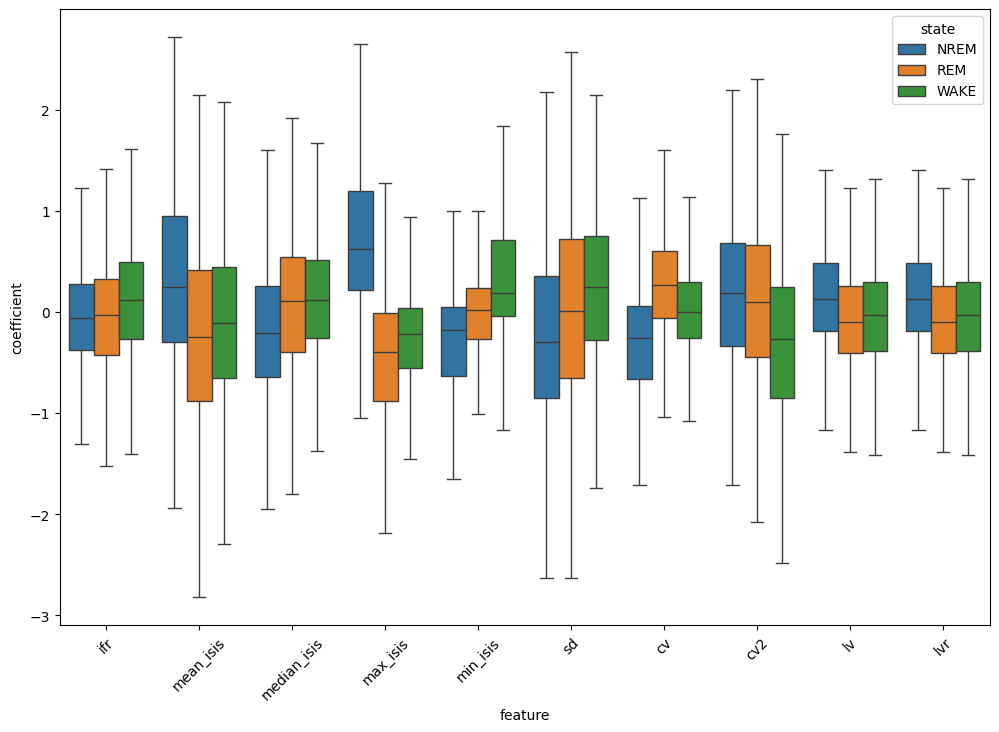

app_ps1-young in total


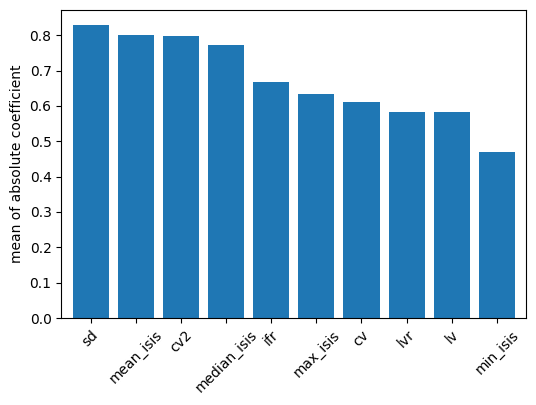

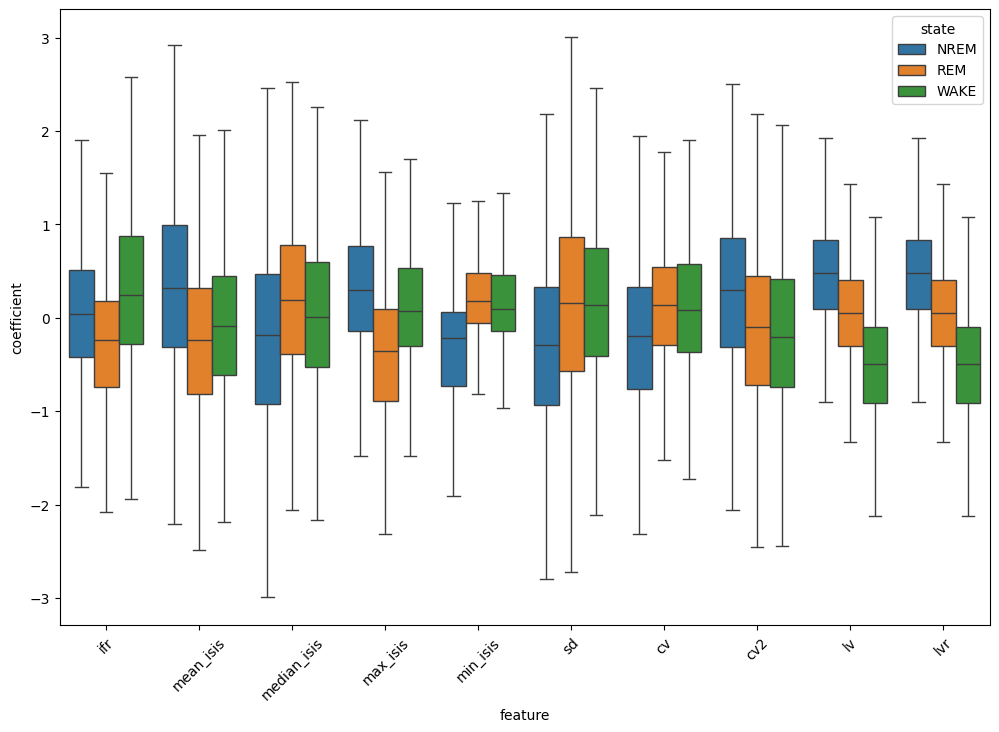

app_ps1-old in total


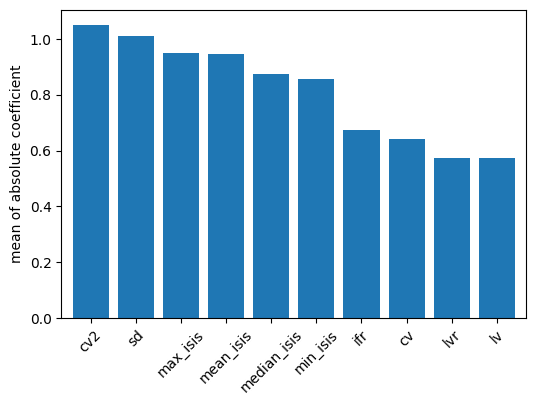

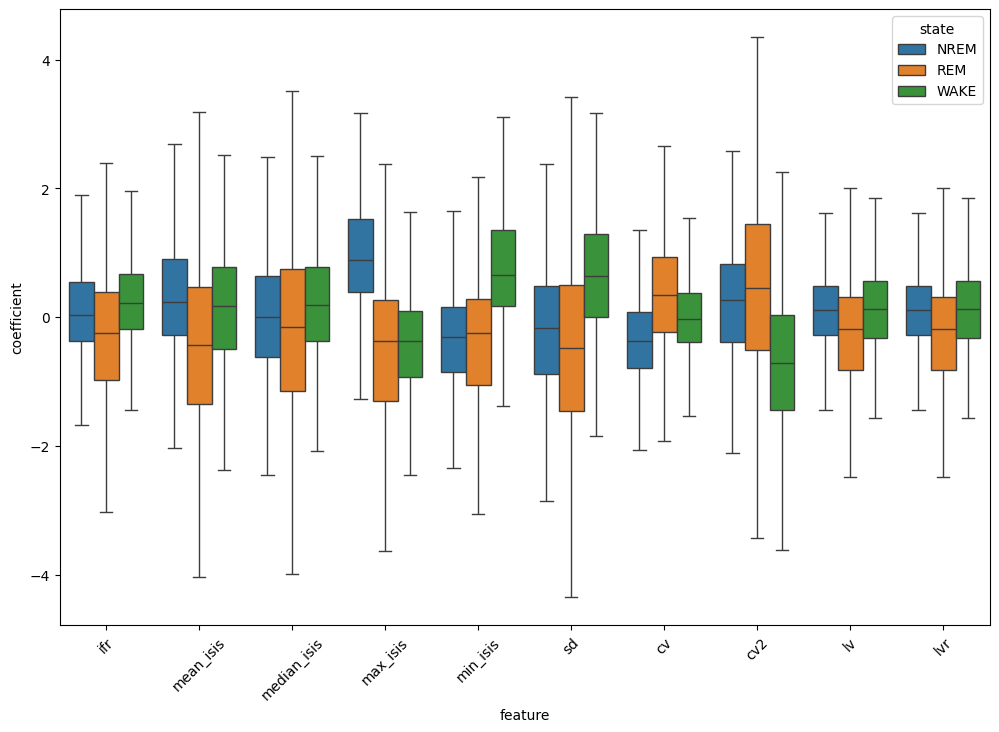

In [148]:
groupings,labels,_,_,_,_ = get_cell_groupings(graphic_train, by_geno=True, by_age=True)
for i, group in enumerate(groupings):
    print(labels[i])
    #print(coefs_df.cell)
    plot_coefs(coefs_df[coefs_df.cell.isin(group)])

In [15]:
basic_xgb_models = train_multi_models(train_scaled, methods=['XGBoost'], sampling_types=['over', 'under'])
basic_xgb_cms = get_cms_multi(test_scaled, basic_xgb_models)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5182/5182 [00:18<00:00, 281.45it/s]


In [16]:
# noma_train = train_scaled[train_scaled['state_length']>16]
# noma_test = test_scaled[test_scaled['state_length']>16]
# basic_log_models_noma = train_multi_models(noma_train, sampling_types=['over', 'under'])
# basic_log_cms_noma = get_cms_multi(noma_test, basic_log_models_noma)
# basic_xgb_models_noma = train_multi_models(noma_train, methods=['XGBoost'], sampling_types=['over', 'under'])
# basic_xgb_cms_noma = get_cms_multi(noma_test, basic_xgb_models_noma)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5179/5179 [00:18<00:00, 286.76it/s]
